In [1]:
import sys
from pathlib import Path

# Add src directory to path
sys.path.insert(0, str(Path.cwd() / '..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

try:
    from arch import arch_model
except ImportError:
    print("Warning: arch package not installed. GARCH modeling will not work.")
    print("Install with: pip install arch")

import matplotlib.dates as mdates

from itertools import product
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, LassoCV, RidgeCV, ElasticNetCV
from sklearn.model_selection import GridSearchCV, cross_val_score, KFold, cross_validate, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Our modules
from src.bt_metrics import *
from src.rebalancing import *
from src.backtest import *
from src.utilities import *
from src.var_functions import *

### Section 1 : data retrieving & creation of monster index

In [2]:
# ── Load dataset ─────────────────────────────────────────────────────────────
data_path = Path("../data/Dataset3_PortfolioReplicaStrategy.xlsx")
df = pd.read_excel(
    data_path , index_col="Ticker", parse_dates=True
)
df.index = pd.to_datetime(df.index)

print("Dataset preview:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df.head())

Dataset preview:
Shape: (705, 15)
Columns: ['MXWO', 'MXWD', 'LEGATRUU', 'HFRXGL', 'RX1', 'TY1', 'GC1', 'CO1', 'ES1', 'VG1', 'NQ1', 'LLL1', 'TP1', 'DU1', 'TU2']


,MXWO,MXWD,LEGATRUU,HFRXGL,RX1,TY1,GC1,CO1,ES1,VG1,NQ1,LLL1,TP1,DU1,TU2
Ticker,,,,,,,,,,,,,,,
2007-10-23,1633.44,414.14,350.2138,1343.63,113.70,110.515625,759.0,82.85,1525.50,4393.0,2212.00,1287.0,1570.5,103.385,103.718750
2007-10-30,1663.89,423.26,352.5413,1356.53,113.79,110.656250,787.8,87.44,1536.00,4476.0,2217.75,1323.9,1610.5,103.410,103.812500
2007-11-06,1651.59,419.51,354.1758,1360.20,113.79,110.875000,823.4,93.26,1525.00,4425.0,2233.50,1320.0,1575.5,103.410,104.046875
2007-11-13,1601.81,405.98,357.2217,1347.16,114.35,111.718750,799.0,88.83,1483.25,4323.0,2066.75,1271.0,1440.5,103.595,104.304688
2007-11-20,1570.74,398.54,359.4446,1335.21,114.72,113.156250,791.4,95.49,1446.00,4296.0,2035.50,1225.2,1472.5,103.800,104.945312



Before computing returns, the candidate set of replicating instruments is restricted from 11 to **10 futures** by removing the `LLL1` contract. The decision is driven by a preliminary inspection of its empirical distribution, which reveals that after June 21st 2011 the price is constant, making the future unsuitable for our analysis.

The replicating universe is consequently defined as
$$
\mathcal{F} \;=\; \{\text{RX1, TY1, GC1, CO1, ES1, VG1, NQ1, TP1, DU1, TU2}\}, \qquad |\mathcal{F}| = 10,
$$
and the set of target indices as
$$
\mathcal{I} \;=\; \{\text{MXWO, MXWD, LEGATRUU, HFRXGL}\}.
$$

In [3]:
FUTURES = ['RX1', 'TY1', 'GC1', 'CO1', 'ES1', 'VG1', 'NQ1', 'TP1', 'DU1', 'TU2']
INDICES = ['MXWO', 'MXWD', 'LEGATRUU', 'HFRXGL']
returns = df[FUTURES + INDICES].pct_change().dropna()


The sample is partitioned chronologically to prevent any look-ahead bias: all exploratory analysis, stationarity testing, GARCH estimation and regression fitting are carried out exclusively on the **training set**, while the **test set** is kept untouched and used only for the final out-of-sample backtest.

$$
\text{Train: } [\,2007\text{-}10\text{-}23,\ 2017\text{-}12\text{-}31\,], \qquad
\text{Test: } [\,2018\text{-}01\text{-}01,\ 2021\text{-}04\text{-}20\,].
$$

The cut-off at the end of 2017 yields roughly an 80/20 split and ensures the test window includes a heterogeneous regime mix — late-cycle bull market, the 2018 volatility spike, and the 2020 COVID shock — providing a stringent assessment of the replication strategy.

In [4]:
# ── Train / Test split ────────────────────────────────────────────────────────
TRAIN_END  = '2017-12-31'
TEST_START = '2018-01-01'


train_data = df[df.index <= TRAIN_END].copy()
test_data  = df[df.index >= TEST_START].copy()

train_returns = train_data.pct_change().dropna()
test_returns = test_data.pct_change().dropna()

print(f"Training: {train_data.index[0].date()} → {train_data.index[-1].date()} ({len(train_data)} weeks)")
print(f"Test:     {test_data.index[0].date()} → {test_data.index[-1].date()} ({len(test_data)} weeks)")

Training: 2007-10-23 → 2017-12-26 (532 weeks)
Test:     2018-01-02 → 2021-04-20 (173 weeks)


The replication target is a synthetic **Monster Index** built as a linear combination of three benchmarks spanning distinct asset classes:

- `MXWO` — global developed equities,
- `LEGATRUU` — global investment-grade fixed income,
- `HFRXGL` — global hedge-fund strategies.

This cross-asset composition makes the tracking problem genuinely non-trivial: no single futures contract can replicate it, forcing the regression to allocate exposure across the full instrument universe $\mathcal{F}$.

Rather than imposing arbitrary capital weights, the components are combined according to a **risk-parity** (inverse-volatility) rule, which equalises the *ex-ante* risk contribution of each constituent. Letting $\hat{\sigma}_i$ denote the annualised standard deviation of component $i$ estimated on the training set,
$$
\hat{\sigma}_i \;=\; \sqrt{52}\,\cdot\,\mathrm{std}\!\left(r_{i,t}\right)_{t \in \mathcal{T}_{\text{train}}}, \qquad i \in \{\text{MXWO, LEGATRUU, HFRXGL}\},
$$
the target weights are defined as
$$
w_i \;=\; \frac{1/\hat{\sigma}_i}{\sum_{j} 1/\hat{\sigma}_j}, \qquad \sum_i w_i = 1, \quad w_i > 0.
$$

The resulting Monster Index return series is then
$$
r^{\,\text{MI}}_t \;=\; \sum_{i \in \mathcal{C}} w_i \, r_{i,t}, \qquad \mathcal{C} = \{\text{MXWO, LEGATRUU, HFRXGL}\}.
$$


Three considerations motivate this choice:

1. **Risk diversification, not capital diversification.** Equally-weighted or market-cap-weighted combinations would be dominated by the most volatile component (equities), making the target behave almost as a pure equity index. Inverse-volatility weighting balances the contribution of bonds, equities and hedge-fund strategies in *risk* space, producing a target with a richer factor structure.
2. **No leverage, no shorts.** Weights are strictly positive and sum to one ($\sum_i |w_i| = 1$), so the Monster Index represents a fully-invested long-only portfolio — a realistic benchmark to replicate.
3. **No look-ahead.** Volatilities are estimated **on the training set only**; the same weights are then applied to the entire sample (training + test), ensuring the target definition is fixed *ex ante* and the out-of-sample backtest in Section 5 remains methodologically clean.

In [5]:
def build_monster_index(data, weights_dict):
    """Weighted combination of index returns. Supports short positions and leverage."""
    return sum(data[col] * w for col, w in weights_dict.items())

# ── Monster Index 1: Defensive ────────────────────────────────────────────────
# 50% HFRXGL, 25% LEGATRUU, 25% MXWO  (leverage 1.00x)
# Defensive allocation: hedge-fund-heavy mix with moderate bond and equity
# exposure. Low-volatility, capital-preservation profile.

TARGET_NAME = 'MI1_Defensive'

COMPONENTS = ['HFRXGL', 'LEGATRUU', 'MXWO']
TARGET_WEIGHTS = {'HFRXGL': 0.50, 'LEGATRUU': 0.25, 'MXWO': 0.25}

# Build target series on full dataset
TARGET_SERIES = build_monster_index(returns, TARGET_WEIGHTS)

print(f"Active Monster Index : {TARGET_NAME}")
print(f"Weights              : {TARGET_WEIGHTS}")
print(f"Leverage (\u03a3|w|)      : {sum(abs(w) for w in TARGET_WEIGHTS.values()):.2f}x")

Active Monster Index : MI1_Defensive
Weights              : {'HFRXGL': 0.5, 'LEGATRUU': 0.25, 'MXWO': 0.25}
Leverage (Σ|w|)      : 1.00x


-----

### Section 2 : EDA & Stationarity Diagnostics

In [6]:
train_monster_index = TARGET_SERIES[TARGET_SERIES.index <= TRAIN_END].copy()
test_monster_index  = TARGET_SERIES[TARGET_SERIES.index >= TEST_START].copy()

We now inspect the empirical properties of the target series $r^{\,\text{MI}}_t$ on the training set through three complementary views: **(i)** density, cumulative growth and drawdown profile; **(ii)** a **QQ-plot** against the Gaussian; **(iii)** the empirical density overlaid with the fitted Normal $\mathcal{N}(\hat\mu, \hat\sigma^2)$.

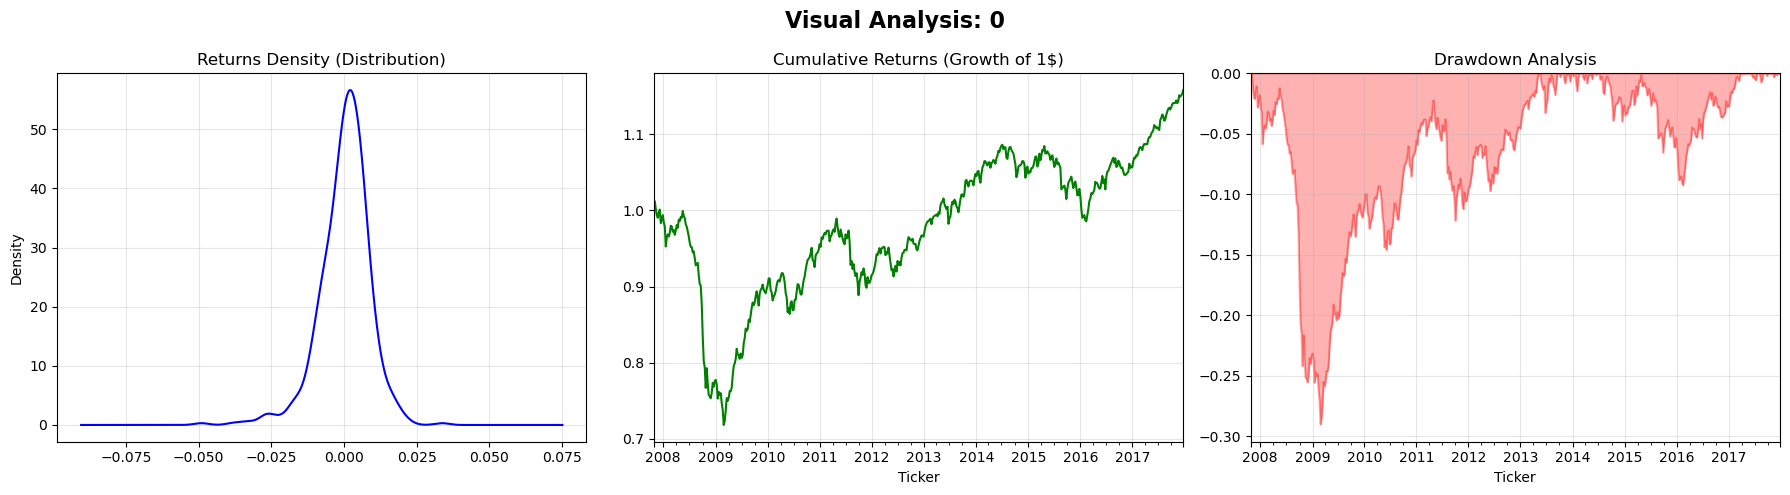

In [7]:
stats_monster_index = calculate_main_metrics(train_monster_index, annual_factor=52, plot=True)

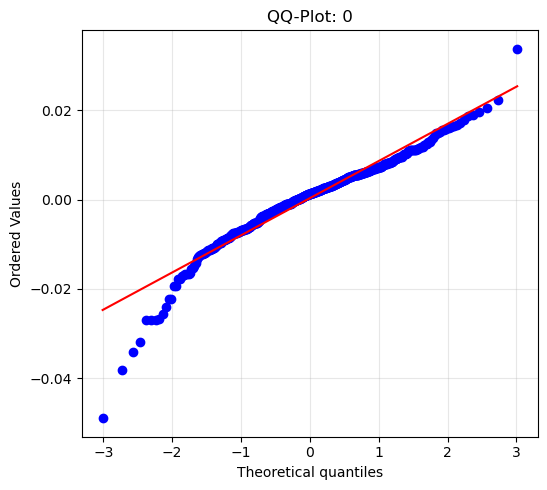

In [8]:
plot_qq(train_monster_index)

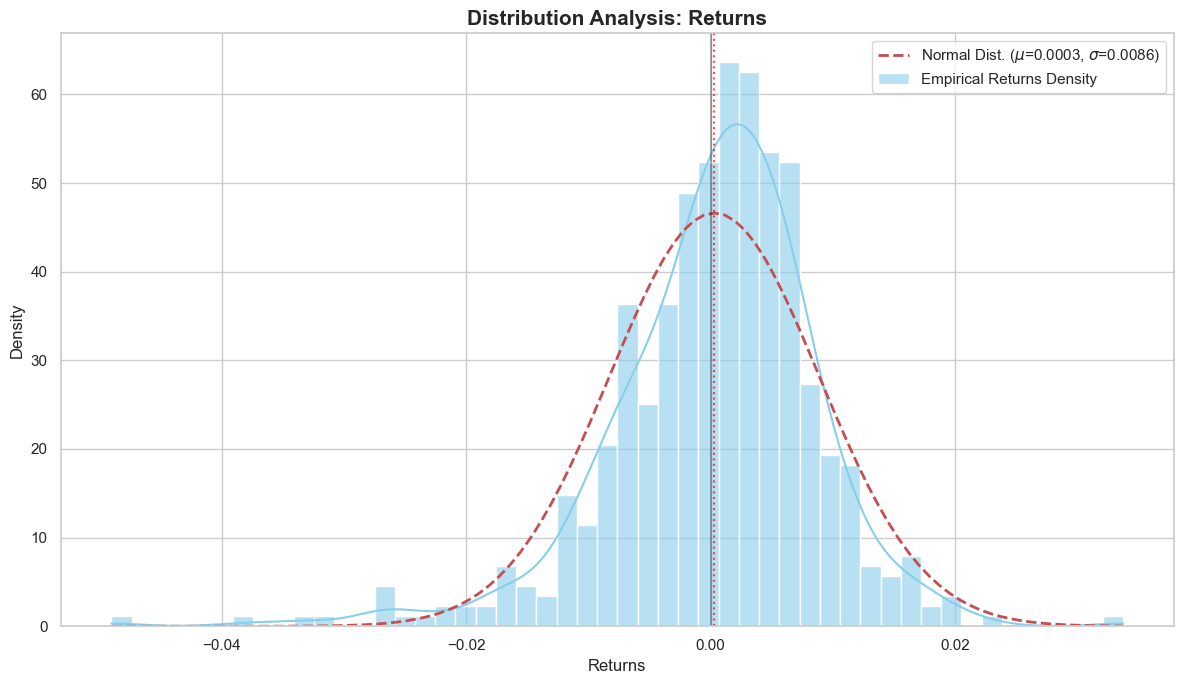

In [9]:
plot_return_dist(train_monster_index)

All three diagnostics consistently reject the Gaussian hypothesis: the QQ-plot exhibits pronounced **left-tail deviations** from the 45° line, the empirical density displays a **sharp peak and heavier tails** than the fitted Normal, and the drawdown panel shows isolated extreme losses inconsistent with thin-tailed dynamics. The Monster Index returns are therefore **leptokurtic and negatively skewed**.

This has direct consequences for the rest of the pipeline:

- **GARCH Models** could be tested with a **t-Student** distribution along with Gaussian, to correctly capture tail behaviour and avoid systematically under-estimating extreme volatility.
- **Risk metrics** such as parametric VaR / ES based on Normal quantiles would understate downside risk; tail-aware alternatives are more appropriate.


We now examine the **static** and **dynamic** linear dependence between the Monster Index and the candidate futures. The static view is provided by the full-sample correlation matrix on the training set; the dynamic view by the **52-week rolling correlation** between $r^{\,\text{MI}}_t$ and the four most relevant contracts (`ES1`, `VG1`, `DU1`, `TU2`), which probes the stability of those linear relationships over time.

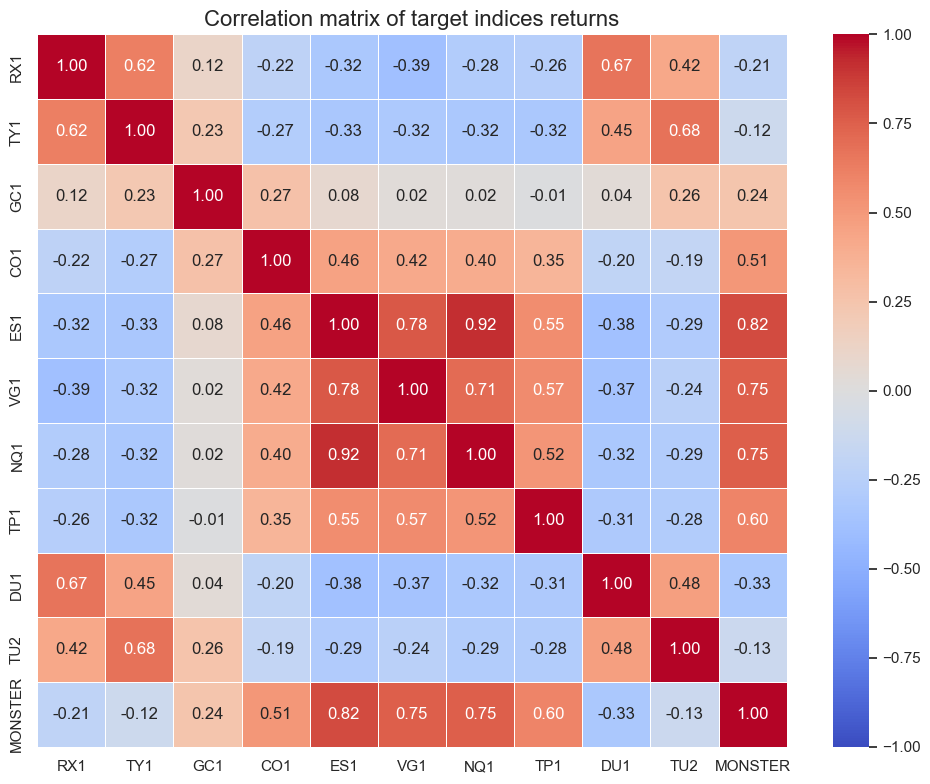

In [10]:
correlation_data = train_returns[FUTURES].copy()
correlation_data['MONSTER'] = train_monster_index
# Create a correlation heatmap for the target indices
plt.figure(figsize=(10, 8))
correlation_matrix = correlation_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, fmt='.2f')
plt.title('Correlation matrix of target indices returns', fontsize=16)
plt.tight_layout()
plt.show()

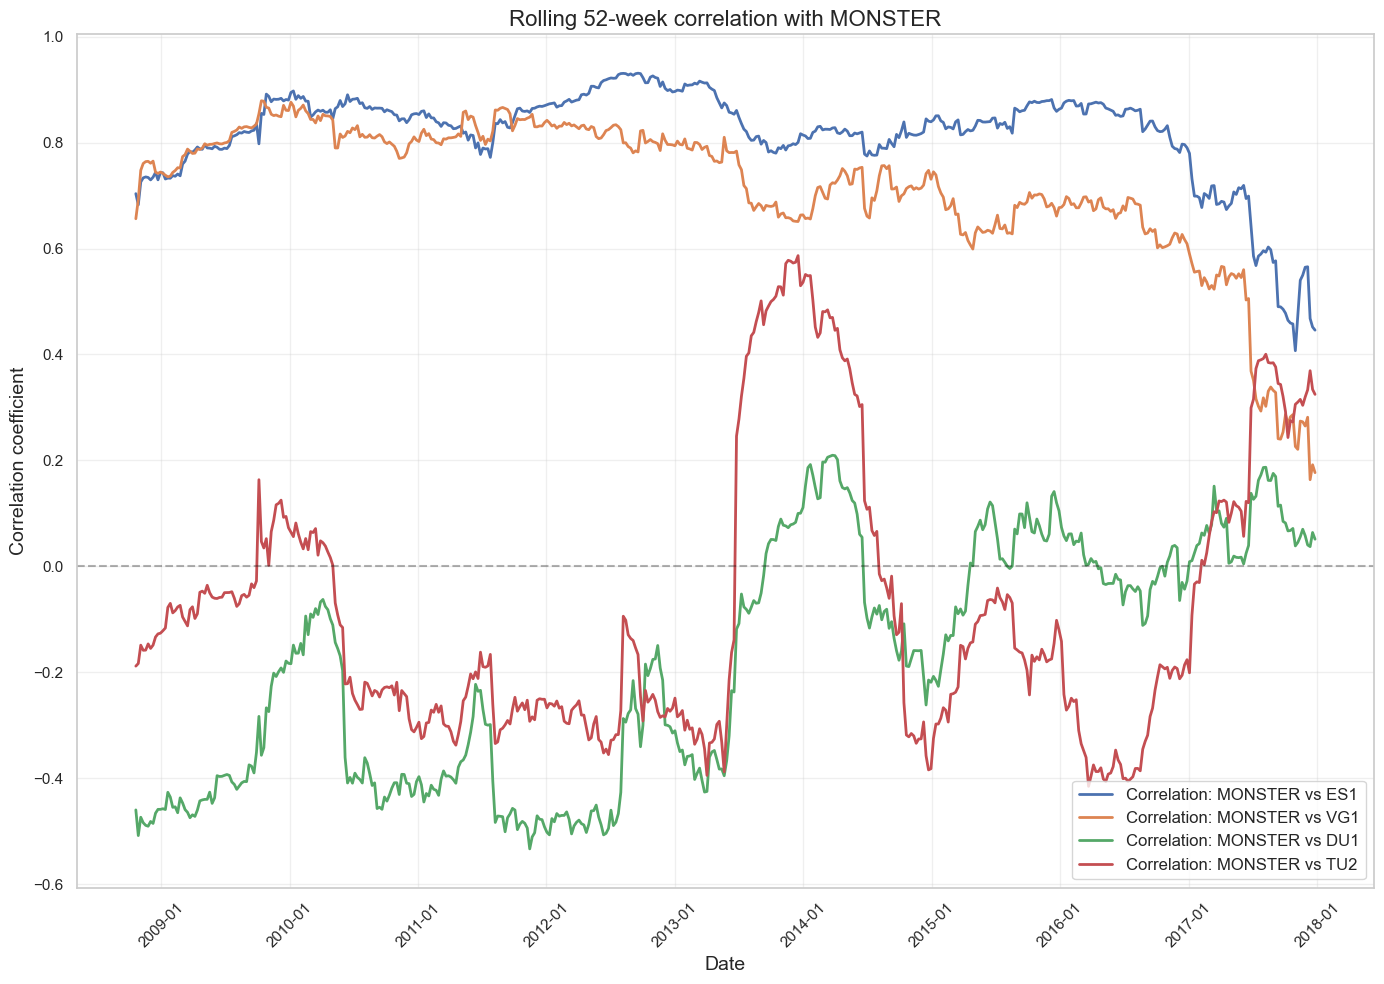

In [11]:

rolling_window = 52  # 52 weeks ≈ 1 year
plt.figure(figsize=(14, 10))

# Base correlation against Monster Index
target_indices = ['ES1', 'VG1' , 'DU1', 'TU2']
base_idx = 'MONSTER'
for idx in [i for i in target_indices ]:
    roll_corr = correlation_data[[base_idx, idx]].rolling(rolling_window).corr().unstack()[base_idx][idx]
    plt.plot(roll_corr.index, roll_corr, linewidth=2,
             label=f"Correlation: {base_idx} vs {idx}")

plt.title(f'Rolling {rolling_window}-week correlation with {base_idx}', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Correlation coefficient', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=12)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The heatmap reveals a **wide spread of correlations** with the Monster Index: strongly positive for equities  and commodities, and weakly correlated for fixed income . This **heterogeneity is desirable** — it provides a rich spectrum of factor exposures for the regression.

The rolling correlation plot shows that these linear dependencies are **far from stable**: equity correlations drift over time and bond-future correlations even flip sign across regimes. This **non-stationarity** argues against a single static OLS fit and motivates the **adaptive rolling-window rebalancing**.

------


Before fitting any econometric model, we verify that the return series satisfy the **weak stationarity** assumption — constant mean, constant variance and time-invariant autocovariance — required by both the GARCH volatility model and the linear tracking regression . We combine a **visual diagnostic** (rolling moments, periodogram, ACF/PACF) with two **complementary statistical tests**: the **Augmented Dickey–Fuller (ADF)**, with null $H_0$: unit root (non-stationarity), and the **KPSS**, with null $H_0$: trend/level stationarity. A series is considered stationary only when **both** tests agree.

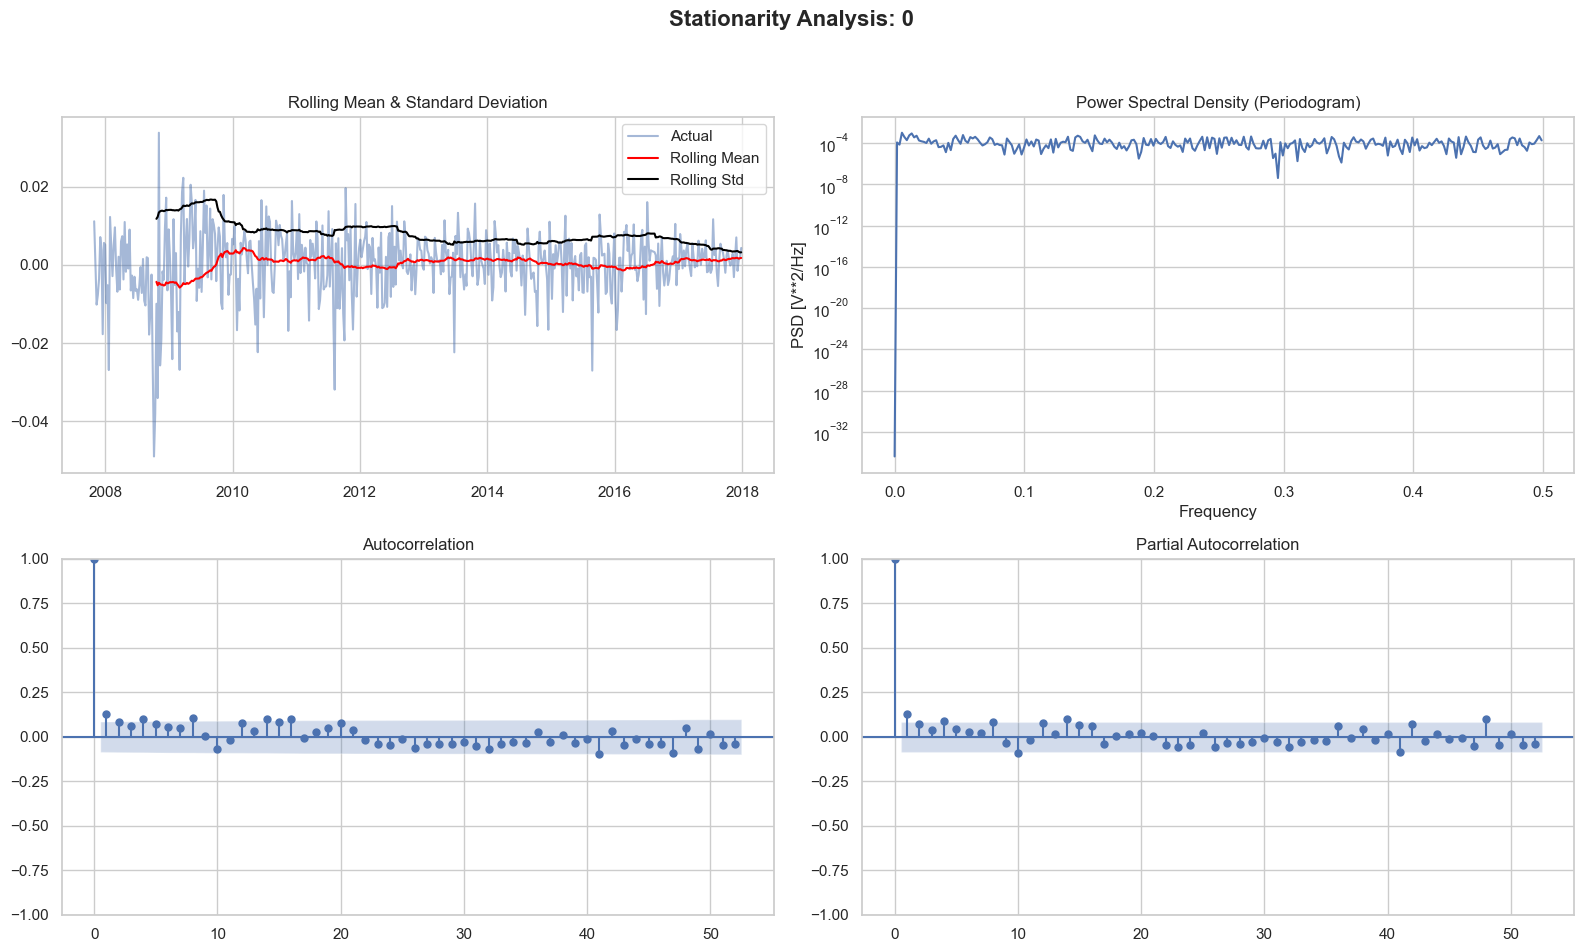

  Stationary (ADF) Stationary (KPSS)
0              Yes               Yes


In [12]:
stationarity_index = stationarity_test(train_monster_index, doPlot=True)
print(stationarity_index[['Stationary (ADF)',
       'Stationary (KPSS)']])

In [13]:
stationarity_futures = stationarity_test(train_returns[FUTURES])
summary_table = stationarity_futures[['Asset', 'Stationary (ADF)', 'Stationary (KPSS)']]

print("--- STATIONARITY CHECK SUMMARY ---")
display(summary_table.sort_values(by='Asset').reset_index(drop=True))

--- STATIONARITY CHECK SUMMARY ---


,Asset,Stationary (ADF),Stationary (KPSS)
0,CO1,Yes,Yes
1,DU1,Yes,Yes
2,ES1,Yes,Yes
3,GC1,Yes,Yes
4,NQ1,Yes,Yes
5,RX1,Yes,Yes
6,TP1,Yes,Yes
7,TU2,Yes,No
8,TY1,Yes,Yes
9,VG1,Yes,Yes



**Monster Index.** Both tests agree on stationarity: the ADF rejects the unit root ($p < 0.05$) while the KPSS fails to reject the stationarity null ($p > 0.05$). The diagnostic plots confirm this finding visually — the **rolling mean** fluctuates around zero with no systematic drift, the **rolling standard deviation** stabilises after the 2008 shock, and the **ACF/PACF** decay almost immediately to within the confidence band, ruling out persistent autoregressive structure in the returns. The **periodogram** is essentially flat across frequencies , with no spectral peak emerging: there is no evidence of deterministic seasonality or cyclical components at the weekly horizon.

**Futures universe.** The joint ADF / KPSS table confirms stationarity for **all ten futures**, the only marginal case being `TU2`, which is rejected by KPSS but accepted by ADF — a mild disagreement attributable to the very low volatility of the 2Y T-Note contract, and not material for the downstream analysis.

The full return panel is therefore suitable for direct use in the GARCH and regression stages without further transformation.

-----

#### Volatility Modelling: GARCH

Stationarity of the **levels** of $r^{\,\text{MI}}_t$ does not imply stationarity of its **conditional variance**. To test for **volatility clustering** we inspect the autocorrelation structure of the squared returns $r_t^{\,2}$, which serve as a model-free proxy for latent variance:
$$
\mathrm{Cov}(r_t^{\,2}, r_{t-h}^{\,2}) \;\neq\; 0 \;\;\Longleftrightarrow\;\; \text{conditional heteroskedasticity.}
$$
Under the hypothesis of i.i.d. returns both ACF and PACF should lie within the confidence band at all lags.

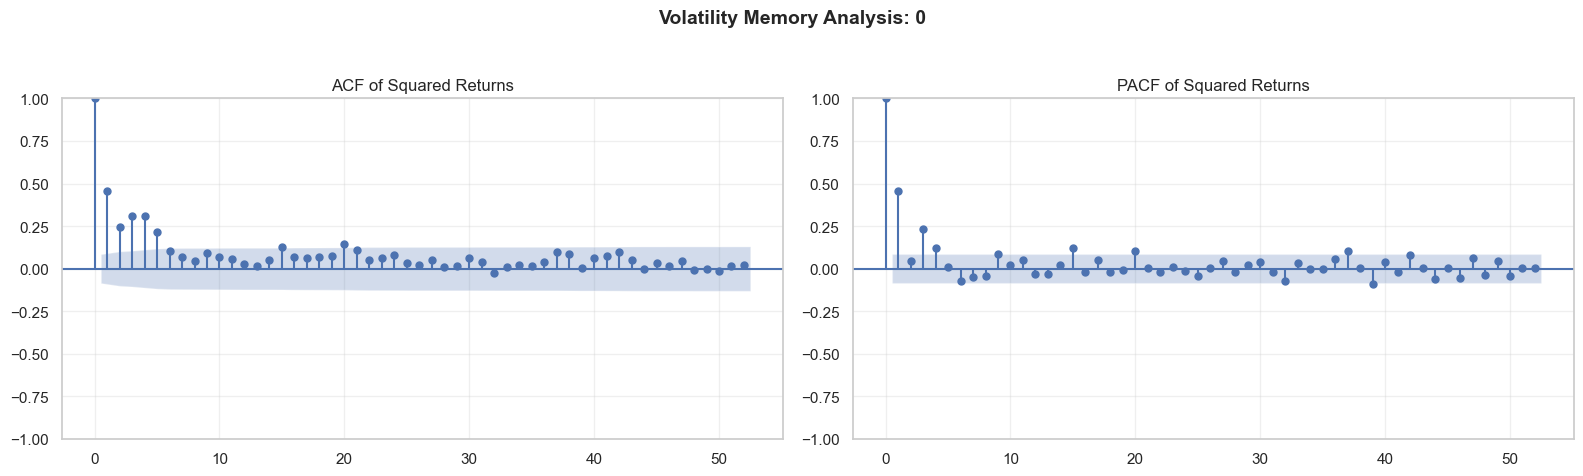

In [14]:
volatility_autocorrelation_test(train_monster_index)


The ACF of the squared returns shows a **slow, monotonic decay** over roughly 7–8 lags before entering the confidence band, while the PACF cuts off after the first few lags. This is the canonical signature of an **ARCH-type process**: shocks to variance are persistent, returns are **conditionally heteroskedastic**, and the i.i.d. assumption is decisively rejected for $r_t^2$.

This finding has several practical consequences:

- **Volatility modelling.** A GARCH(1,1) specification — possibly with asymmetric (GJR) leverage term and $t$-Student innovations to match the leptokurtosis documented above — is the natural candidate to capture this dynamics.
- **Downstream uses.** The fitted $\hat{\sigma}_t$ could be plugged into **parametric VaR / ES** at the desired confidence level, used as a **scaling factor** in risk-budgeting and portfolio optimisation, or exploited as a **regime indicator** to trigger conservative rebalancing during high-volatility periods.

**Rolling GARCH — Grid Search Design**

We estimate the conditional volatility of the Monster Index through a **rolling-window GARCH** procedure, refitted at each weekly step on the previous $W$ observations and used to forecast one-step-ahead variance. This out-of-sample design mirrors the operational setting of the replication strategy and avoids in-sample overfitting.

For each rolling window the conditional variance follows a **GJR-GARCH(1,$o$,1)** specification,
$$
\sigma_t^{\,2} \;=\; \omega \;+\; \alpha\, \varepsilon_{t-1}^{\,2} \;+\; \gamma\, \varepsilon_{t-1}^{\,2}\,\mathbb{1}_{\{\varepsilon_{t-1}<0\}} \;+\; \beta\, \sigma_{t-1}^{\,2},
$$
which collapses to the standard GARCH(1,1) for $o = 0$ and to GJR-GARCH for $o \geq 1$, where $\gamma > 0$ captures the **leverage effect** (negative shocks raise future volatility more than positive ones of equal magnitude).

A 3-dimensional grid is explored over:

- **Window size** $W \in \{26,\ 52,\ 104\}$ weeks — controls the bias/variance trade-off between adaptivity and parameter stability;
- **Asymmetry order** $o \in \{0, 1, 2\}$ — tests the relevance of the leverage effect;
- **Residuals distribution** $\varepsilon_t / \sigma_t \sim \mathcal{D}$, with $\mathcal{D} \in \{\mathcal{N},\ \text{t-Student}\}$ — motivated by the heavy-tailed empirical density observed in Section 1.5.

Each configuration is summarised by the **mean AIC and BIC** across all rolling fits; for the $t$-Student specifications we also track the average estimated degrees of freedom $\hat{\nu}$, where $\hat{\nu} \to \infty$ would indicate convergence back to a Gaussian regime. Returns are rescaled by 100 to improve the conditioning of the likelihood optimiser.

In [15]:
# --- 1. Grid Definition ---
configs = [
    (26, 1, 'Normal'),
    (26, 2, 'Normal'),
    (52, 1, 't'),
]

# Dictionary to store the resulting pd.Series for each combination
garch_results = {}
garch_metrics = []

# --- 2. Grid Search Loop ---
for wd, o, d in configs:

    # Create a clean key for our dictionary
    config_key = f"wd:{wd}_o:{o}_dist:{d}"
    print(f"Running grid search for: {config_key}...")

    # Generate the rolling window pipeline for the current window size
    pipeline = rolling_window_pipeline(train_monster_index, window_size=wd, step=1)

    forecasts = []
    forecast_dates = []

    # Temporary lists to store metrics for each rolling step
    step_aics = []
    step_bics = []
    step_nus = []

    # Iterate through each temporal step in the pipeline
    for step_context in pipeline:

        # Extract data safely (using copy to avoid SettingWithCopyWarning)
        train_set = step_context['train'].copy()
        forecast_date = step_context['forecast_date']

        # --- 3. Scaling ---
        # Multiply by 100 to feed the optimizer a variance between 1 and 1000
        train_scaled = train_set * 100


        # --- 4. Model Fitting ---
        # mean='Zero' because we handled the mean manually above
        model = arch_model(train_scaled, vol='Garch', p=1, q=1, o=o, mean='Constant', dist=d)

        # Catching potential non-convergence gracefully
        try:
            model_fit = model.fit(disp='off')
        except Exception as e:
            # If a specific configuration fails (e.g., matrix inversion error), append NaN
            forecasts.append(np.nan)
            forecast_dates.append(forecast_date)
            continue

        # Extract and store metrics for this specific step
        step_aics.append(model_fit.aic)
        step_bics.append(model_fit.bic)
        if d in ['t', 'skewt']:
            step_nus.append(model_fit.params.get('nu', np.nan))

        # --- 5. Forecast & Update ---
        # We use the built-in method because it automatically adjusts the math
        # whether it's a GARCH(1,1) or a GJR-GARCH(1,o,1)
        forecast = model_fit.forecast(horizon=1, align='origin')

        # Extract the predicted variance for t+1 (the last row of the variance dataframe)
        pred_var_scaled = forecast.variance.iloc[-1, 0]

        # --- 6. Rescale Back to Original ---
        # We applied * 100 to returns, so variance is * 10,000.
        # We take the square root to get std dev, then divide by 100.
        pred_vol = np.sqrt(pred_var_scaled) / 100

        # Store results for this specific rolling step
        forecasts.append(pred_vol)
        forecast_dates.append(forecast_date)

    # --- 7. Save Intelligent Output ---
    # Convert the lists into a proper Pandas Series indexed by dates
    garch_results[config_key] = pd.Series(forecasts, index=forecast_dates)

    # --- 8. Save Metrics Summary for this Configuration ---
    # Calculate the mean of the metrics across all rolling windows
    config_summary = {
        'Config': config_key,
        'Window': wd,
        'Asymmetry (o)': o,
        'Distribution': d,
        'Mean AIC': np.nanmean(step_aics) if step_aics else np.nan,
        'Mean BIC': np.nanmean(step_bics) if step_bics else np.nan,
        'Mean nu (df)': np.nanmean(step_nus) if step_nus else np.nan
    }
    garch_metrics.append(config_summary)

print("\n--- Grid Search Completed! ---")
print(f"Total configurations tested: {len(garch_results)}")

# --- 10. Create the metrics_df ---
metrics_df = pd.DataFrame(garch_metrics)
metrics_df.set_index('Config', inplace=True)
metrics_df = metrics_df.T

Running grid search for: wd:26_o:1_dist:Normal...
Running grid search for: wd:26_o:2_dist:Normal...
Running grid search for: wd:52_o:1_dist:t...

--- Grid Search Completed! ---
Total configurations tested: 3


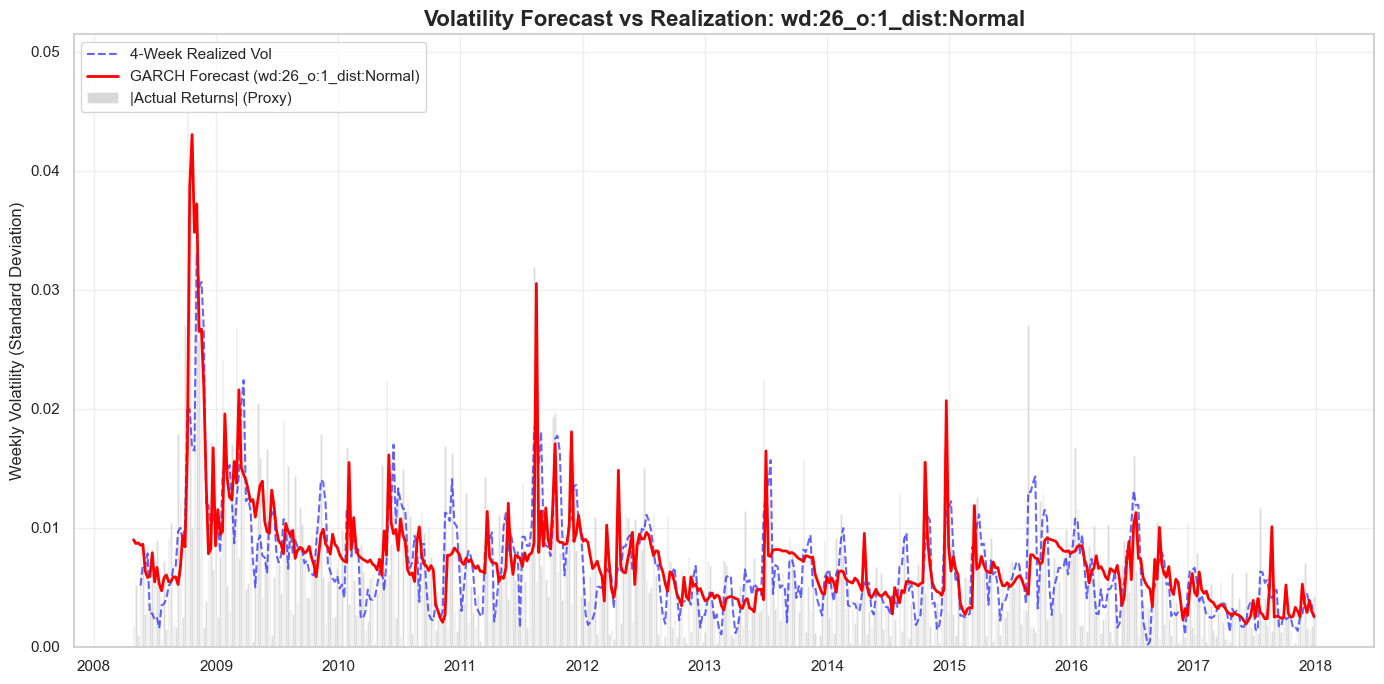

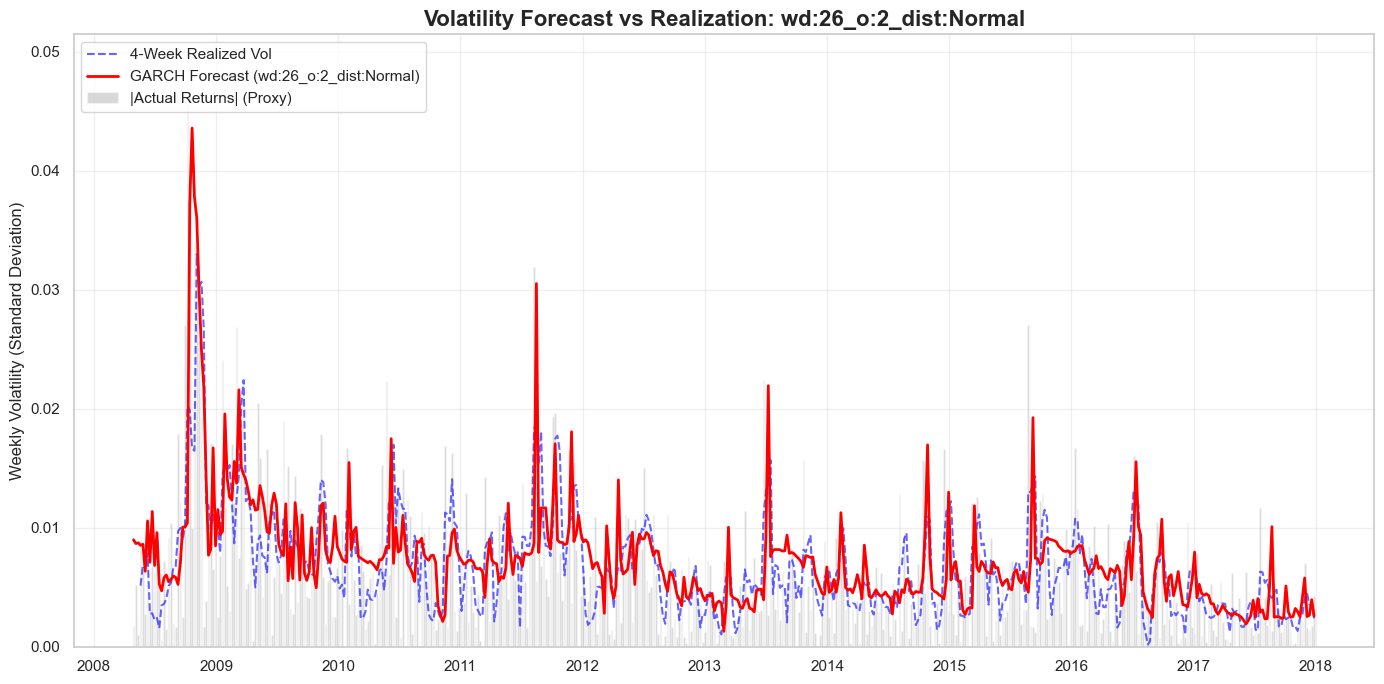

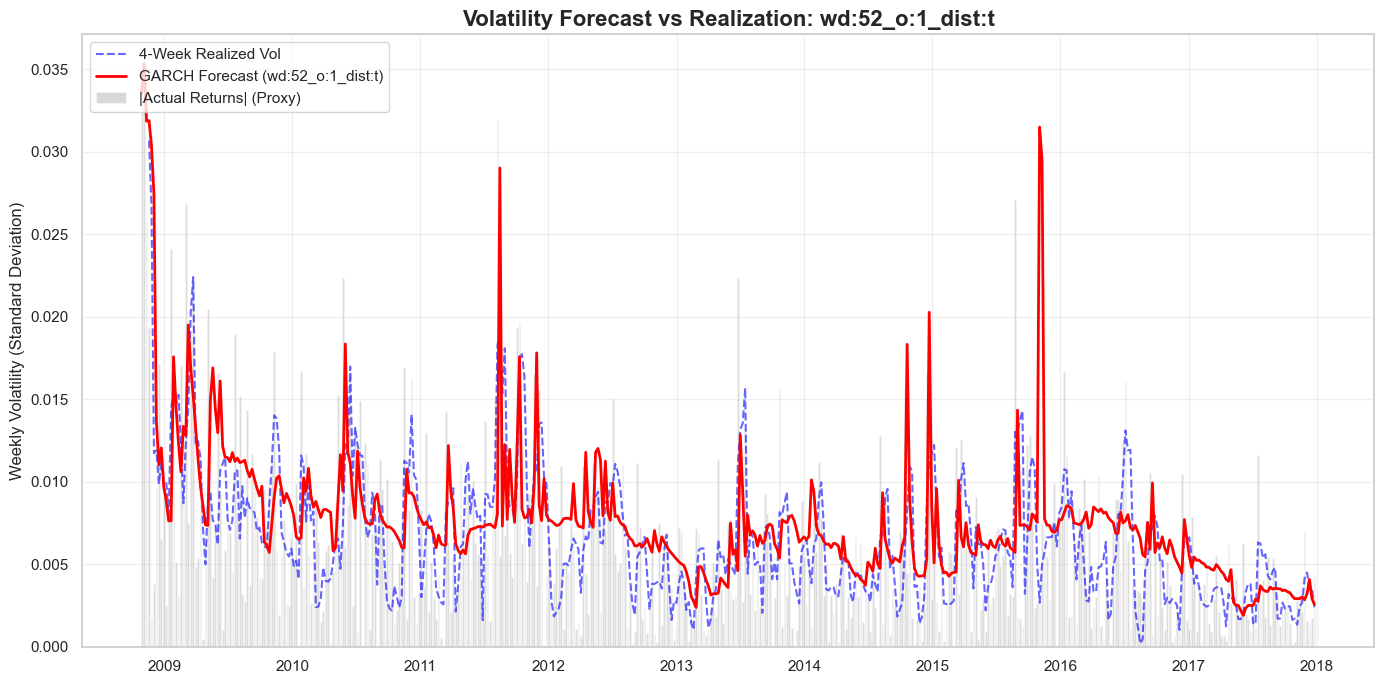

In [16]:
for model_name in garch_results.keys():
    plot_garch_performance(train_monster_index, garch_results[model_name], model_name=model_name)


#### Selected GARCH Configurations

After the full grid search, we narrowed down to three configurations that showed the best
out-of-sample performance — though the differences were modest:

- **GARCH(1,1,1) — window 26, Normal**: best short-window asymmetric fit
- **GARCH(1,2,1) — window 26, Normal**: slight improvement in asymmetry capture over o=1
- **GARCH(1,1,1) — window 52, Student-t**: better tail modelling over a longer window but with **occasional large spikes** absent in the Normal counterparts: this is the expected effect of heavier tails inflating the estimated unconditional variance after rare large shocks.

The outperformance vs. the remaining configurations was marginal,
but these three offered the best AIC/BIC trade-off across the rolling windows.



To confirm that the GARCH dynamics have effectively absorbed the volatility clustering, we examine the autocorrelation of the **squared standardised residuals**
$$
z_t^{\,2} \;=\; \left(\frac{r_t}{\hat{\sigma}_t}\right)^{2}.
$$
If the model is correctly specified, $\{z_t^{\,2}\}$ should behave as an i.i.d. sequence and both its ACF and PACF should lie inside the confidence band at all lags — i.e. no exploitable variance structure should remain.

--- RUNNING DIAGNOSTIC PLOTS ---


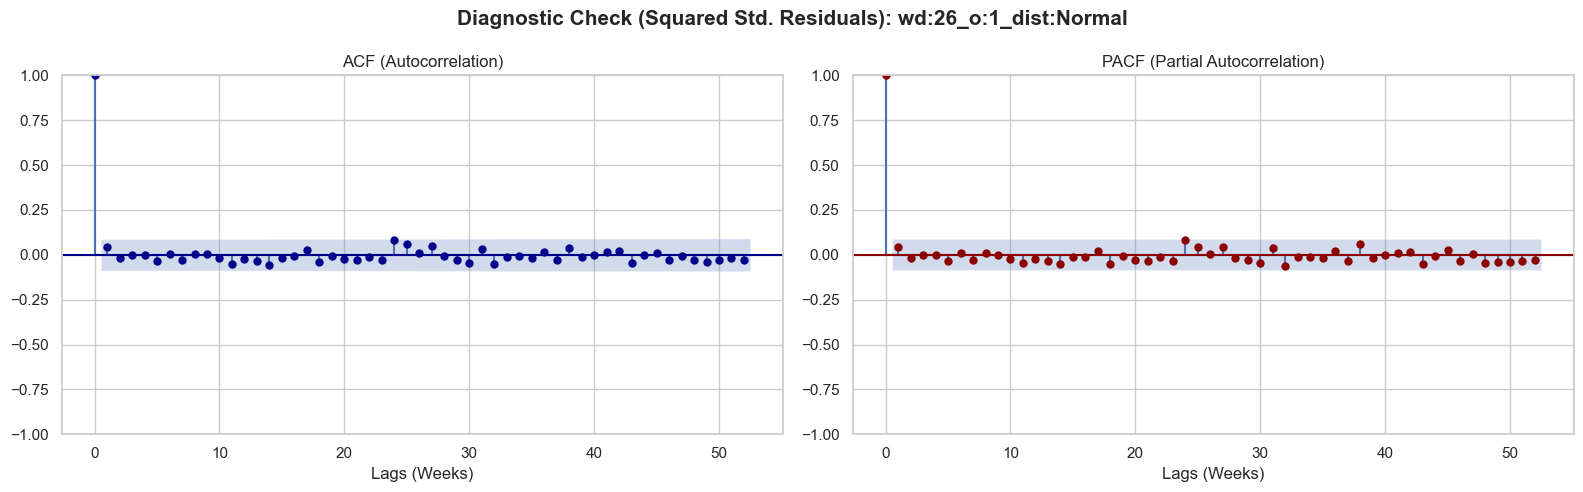

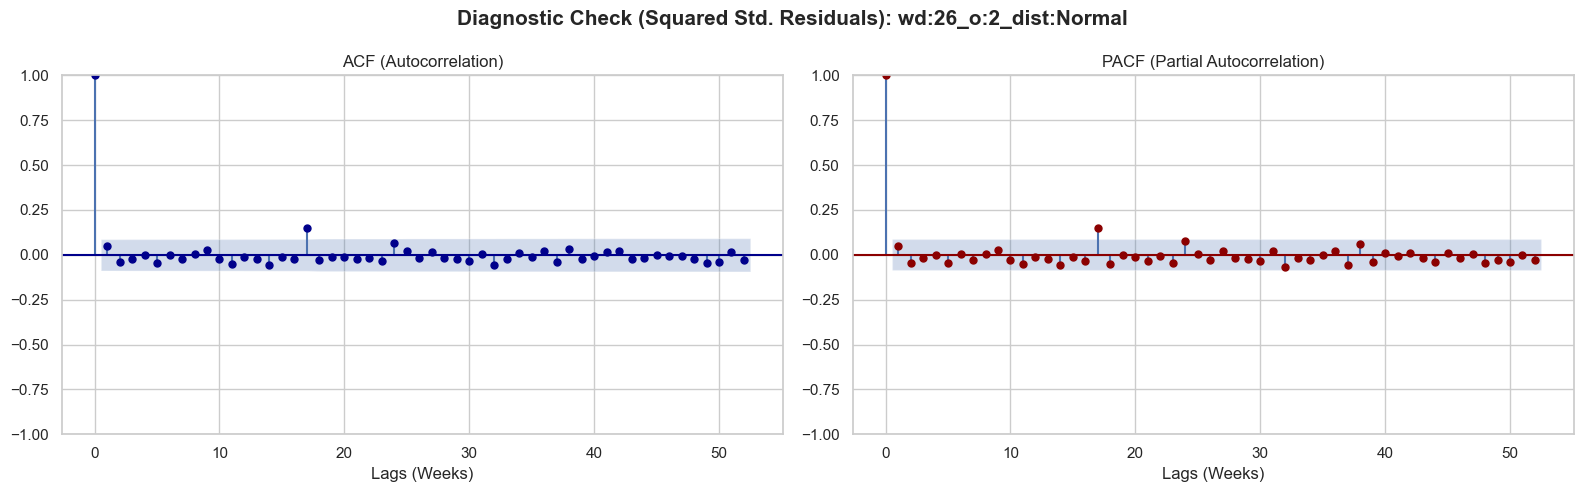

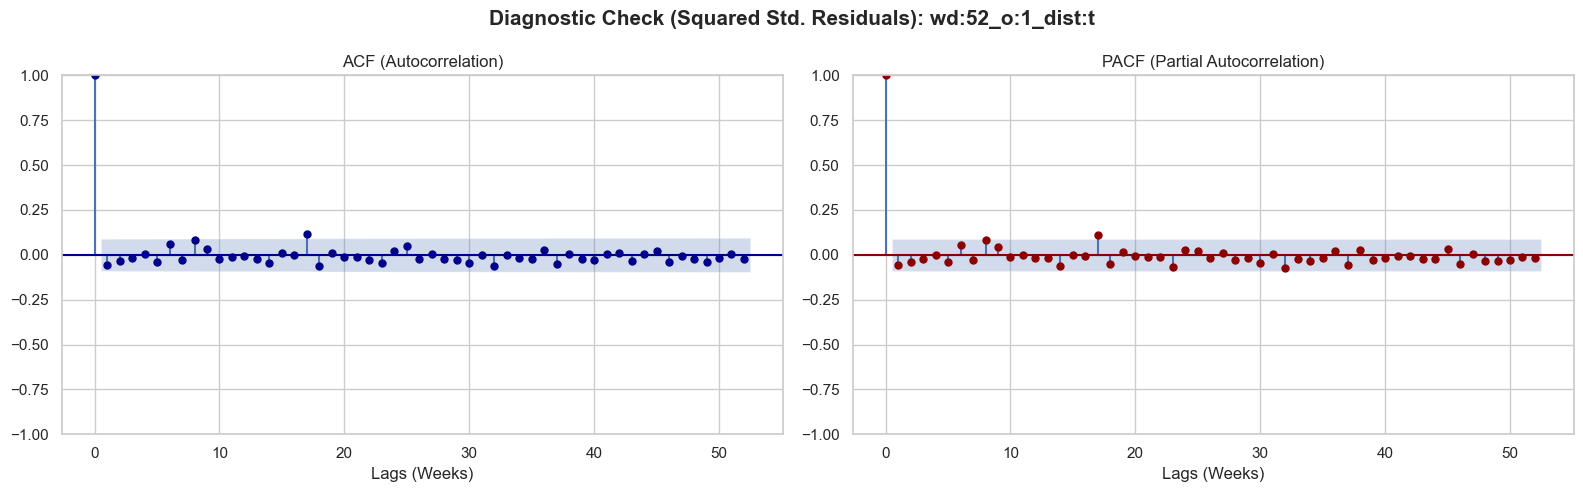

In [17]:
# --- Iterate over the garch_results dictionary ---

print("--- RUNNING DIAGNOSTIC PLOTS ---")

# Convert items to a list to easily slice it.
# Tip: You can sort metrics_df first and iterate over its index to plot only the "Best" models!
for config_key, predicted_vol in list(garch_results.items()):
    if config_key in garch_results:
        # We pass the original MONSTER returns, the predicted series, and the name
        check_residual_autocorrelation(
            actual_returns=correlation_data['MONSTER'],
            predicted_vol_series=predicted_vol,
            model_name=config_key,
            max_lags=52 # Looking back 1 full year of weekly lags
        )


The ACF/PACF plots of $z_t^{\,2}$ display **no significant spike beyond the confidence band** at any lag up to 52 weeks, in stark contrast with the slowly-decaying pattern observed above on the raw squared returns. The GARCH specification has therefore **fully absorbed the conditional heteroskedasticity** of the Monster Index: the residual variance is statistically indistinguishable from white noise, validating the use of the fitted $\hat{\sigma}_t$ series in the downstream risk and rebalancing logic.

---
### Section 3 — Model Selection

We replicate the Monster Index using four linear models — **OLS, Lasso, Ridge, and Elastic Net** — applied through a **rolling window backtest** on the training set.


In [18]:
# ── VaR functions —─────────────────────────────────────
# calculate_var     : Gaussian parametric VaR
# calculate_var_hs  : Historical Simulation VaR
# calculate_var_whs : Weighted Historical Simulation VaR (lambda=0.97)
from src.var_functions import *

# ── Rolling windows: 1Y / 2Y / 3Y — shared by all four models ───────────────
ROLLING_WINDOWS = [52, 104, 156]

# ── VaR global parameters ────────────────────────────────────────────────────
VAR_CONFIDENCE    = 0.01   # 1% confidence level
VAR_HORIZON       = 4      # 4-week horizon (~1 month)
MAX_VAR_THRESHOLD = 0.08   # Internal prudential threshold (8%)
                            # UCITS legal limit is 20%.
                            # With current models gross exposure ~0.20x
                            # keeps VaR well below 8% — constraint rarely active.

print(f"Rolling windows : {ROLLING_WINDOWS} weeks")
print(f"VaR parameters  : {VAR_CONFIDENCE*100:.0f}% confidence, "
      f"{VAR_HORIZON}w horizon, threshold={MAX_VAR_THRESHOLD*100:.0f}%")


Rolling windows : [52, 104, 156] weeks
VaR parameters  : 1% confidence, 4w horizon, threshold=8%


Due to the non-Gaussian, heavy-tailed nature of hedge fund returns, we adopt **Weighted Historical Simulation (WHS)**
for VaR estimation — no distributional assumptions, with recent observations weighted more heavily via exponential decay.

### 3.2 — Shared Backtest Engine

All four models run through a single `run_model()` function, ensuring full comparability. The only differences between models are the `model_class` and `param_grid` arguments passed in.

#### `cv_grid_search`

Selects the optimal hyperparameters for a given model using **TimeSeriesSplit cross-validation** on the current rolling window. Key design choices:

- Fold ordering is strictly chronological — the validation set is always *after* the training set, preventing any look-ahead bias.
- Normalization is **re-fit independently on each fold's training data**, so the scaler never sees the validation distribution.
- The selection criterion is **mean Tracking Error across folds** — selects the configuration minimizing return deviations on unseen validation data, directly aligned with the replication objective.

Cross-validation is skipped for OLS, which has no hyperparameter to tune.

#### `run_model`

Executes the full rolling backtest. At each step $t$:

1. **Window extraction** — the model trains on the $K$ most recent observations $[t-K,\, t)$; the prediction target is $t+1$ (strictly out-of-sample).
2. **Normalization** — separate `MinMaxScaler` for $X$ and $y$, fit on the current window only.
3. **Hyperparameter selection** — `cv_grid_search` is called if the grid contains more than one configuration; otherwise the single entry is used directly (OLS).
4. **Model fit** — the model is refit on the full window with the selected parameters.
5. **Weight rescaling** — coefficients estimated in normalized space are mapped back to original units: $\beta^{\text{orig}}_j = \beta^{\text{norm}}_j / s_j$, where $s_j$ is the MinMax scale of feature $j$.
6. **VaR constraint** — once at least 12 replica returns are available, the portfolio VaR is estimated by applying the *current* weights ww
w retrospectively to the trailing up-to-52-week window of futures returns, using the selected method (`whs` by default). This measures the risk of the *current* position, not of past positions. If VaR exceeds the internal threshold of 8%, weights are scaled down proportionally: $w \leftarrow w \cdot \frac{\text{threshold}}{\text{VaR}}$​.
7. **Out-of-sample prediction** — the replica return at $t+1$ is $\hat{r}_{t+1} = w^\top r^F_{t+1}$, where $r^F_{t+1}$ is the vector of futures returns never seen during training.


#### `get_best_config` — Window Selection

The best rolling window is selected according to the following priority order:

1. **Tracking Error** — primary criterion. TE directly measures the quality of the
replica and is therefore the natural basis for window selection.
The window with the lowest absolute TE is selected first.
2. **Correlation** — tiebreaker. If two or more windows produce identical TE (within floating-point tolerance), the one with the highest correlation to the target is preferred.
3. **Information Ratio** — not used for selection. In passive replication, IR close to zero is desirable but structurally unachievable when replicating hedge-fund indices with linear instruments.



In [19]:

def cv_grid_search(y_train, X_train, model_class, param_grid, rolling_window, n_splits=5):
    """
    TimeSeriesSplit CV for hyperparameter selection.
    Always trains on past, validates on future — no leakage.
    Normalization is re-fit within each fold.
    Selection criterion: mean Tracking Error across folds (annualized, weekly data).
    """
    tscv = TimeSeriesSplit(
        n_splits=n_splits,
        test_size=max(1, rolling_window // (n_splits + 1))
    )
    cv_scores = {}
    for params in param_grid:
        fold_te = []
        for tr_idx, val_idx in tscv.split(X_train):
            Xtr = X_train[tr_idx]; ytr = y_train[tr_idx]
            Xv  = X_train[val_idx]; yv  = y_train[val_idx]
            if len(Xtr) < 10:
                continue
            sX    = MinMaxScaler(); Xtr_n = sX.fit_transform(Xtr); Xv_n = sX.transform(Xv)
            sY    = MinMaxScaler()
            ytr_n = sY.fit_transform(ytr.reshape(-1, 1)).flatten()
            m     = model_class(fit_intercept=False, **params)
            m.fit(Xtr_n, ytr_n)
            yp    = sY.inverse_transform(m.predict(Xv_n).reshape(-1, 1)).flatten()
            fold_te.append(np.std(yv - yp) * np.sqrt(52))
        if fold_te:
            cv_scores[str(params)] = (np.mean(fold_te), params)
    best_key = min(cv_scores, key=lambda k: cv_scores[k][0])
    return cv_scores[best_key][1], {'cv_scores': cv_scores}


def run_model(y, X, rolling_window, model_class, param_grid,
              model_name='Model',
              var_confidence=VAR_CONFIDENCE,
              var_horizon=VAR_HORIZON,
              max_var_threshold=MAX_VAR_THRESHOLD,
              var_method='whs'):
    """
    Generic rolling window backtest with VaR-based position scaling.

    Parameters
    ----------
    var_method : str, default 'whs'
        VaR estimation method. One of:
          'whs'      Weighted Historical Simulation (recency-weighted, lambda=0.97)
          'hs'       Historical Simulation (equal weights, non-parametric)
    """
    # ── Select VaR function ───────────────────────────────────────────────────
    if var_method == 'whs':
        var_fn = calculate_var_whs
    elif var_method == 'hs':
        var_fn = calculate_var_hs


    common_idx  = y.index.intersection(X.index)
    y = y.loc[common_idx]; X = X.loc[common_idx]
    y_values = y.values; X_values = X.values; dates_array = y.index

    weights_history  = []; replica_returns = []; target_dates    = []
    gross_exposures  = []; var_values      = []; scaling_factors = []
    selected_params  = []; weight_stability = []; prev_weights   = None

    for i in range(len(y) - rolling_window - 1):
        end_idx = i + rolling_window
        X_tr = X_values[i:end_idx]; y_tr = y_values[i:end_idx]

        sX = MinMaxScaler(); X_n = sX.fit_transform(X_tr)
        sY = MinMaxScaler(); y_n = sY.fit_transform(y_tr.reshape(-1, 1)).flatten()

        if len(param_grid) > 1:
            best_params, _ = cv_grid_search(y_tr, X_n, model_class,
                                            param_grid, rolling_window)
        else:
            best_params = {k: v for k, v in param_grid[0].items()}

        selected_params.append(best_params)
        m = model_class(fit_intercept=False, **best_params)
        m.fit(X_n, y_n)
        w = m.coef_ / sX.scale_

        if prev_weights is not None:
            weight_stability.append(np.sqrt(np.sum((w - prev_weights) ** 2)))
        prev_weights = w.copy()

        sf = 1.0
        if len(replica_returns) >= 12:
            hr  = [np.dot(X_values[end_idx - (len(replica_returns) - j)], w)
                   for j in range(max(0, len(replica_returns) - 52), len(replica_returns))]
            var = var_fn(hr, confidence=var_confidence, horizon=var_horizon)
            if var > max_var_threshold:
                sf  = max_var_threshold / var; w = w * sf
                var = var_fn([r * sf for r in hr],
                             confidence=var_confidence, horizon=var_horizon)
            var_values.append(var)
        else:
            var_values.append(np.nan)

        scaling_factors.append(sf)
        gross_exposures.append(np.sum(np.abs(w)))
        weights_history.append(w.copy())
        replica_returns.append(np.dot(X_values[end_idx], w))
        target_dates.append(dates_array[end_idx])

    rep     = pd.Series(replica_returns, index=target_dates)
    tgt     = y.loc[rep.index]
    cum_rep = (1 + rep).cumprod()
    cum_tgt = (1 + tgt).cumprod()
    lb1, lb4, lb8 = ljung_box(rep, tgt)
    metrics = compute_metrics(rep, tgt)

    return {
        **metrics,
        'model':                model_name,
        'rolling_window':       rolling_window,
        'var_method':           var_method,
        'lb_pval_lag1':         lb1,
        'lb_pval_lag4':         lb4,
        'lb_pval_lag8':         lb8,
        'avg_gross_exposure':   np.mean(gross_exposures),
        'avg_var':              np.nanmean(var_values),
        'replica_returns':      rep,
        'aligned_target':       tgt,
        'cumulative_replica':   cum_rep,
        'cumulative_target':    cum_tgt,
        'weights_history':      weights_history,
        'gross_exposures':      gross_exposures,
        'var_values':           var_values,
        'scaling_factors':      scaling_factors,
        'selected_params':      selected_params,
        'weight_stability':     weight_stability,
        'avg_weight_stability': np.mean(weight_stability) if weight_stability else np.nan,
    }

def get_best_config(results_dict):
    windows = list(results_dict.keys())

    tes   = {w: results_dict[w]['tracking_error']         for w in windows}
    corrs = {w: results_dict[w]['correlation']            for w in windows}
    irs   = {w: abs(results_dict[w]['information_ratio']) for w in windows}

    # Step 1: window with minimum Tracking Error
    best_window = min(windows, key=lambda w: tes[w])

    # Step 2: correlation tiebreaker
    min_te = tes[best_window]
    ties   = [w for w in windows if abs(tes[w] - min_te) < 1e-6]
    if len(ties) > 1:
        best_window = max(ties, key=lambda w: corrs[w])

    # Transparency table
    table = pd.DataFrame({
        'Window':   windows,
        'TE (%)':   [round(tes[w] * 100, 3) for w in windows],
        'Corr':     [round(corrs[w], 4)      for w in windows],
        'abs(IR)':  [round(irs[w], 3)        for w in windows],
        'Selected': ['★' if w == best_window else '' for w in windows],
    }).sort_values('TE (%)')

    print("Window selection — sequential priority (TE → Corr → |IR|):")
    print(table.to_string(index=False))
    print(f"→ Selected window: {best_window}w")

    return results_dict[best_window], best_window

------

Hyperparameter grids are designed to cover several orders of magnitude, reflecting the wide range of regularization strengths that may be optimal across different rolling windows and market regimes.

- **Lasso** (9 configs): `alpha` spans $[10^{-5}, 10^{-1}]$ on a logarithmic scale. The lower bound allows near-OLS solutions; the upper bound produces aggressive sparsity. `max_iter=10000` and `tol=1e-4` ensure convergence on the normalized data.
- **Ridge** (12 configs): `alpha` spans $[10^{-4}, 100]$, a wider range than Lasso reflecting the different scale of L2 vs L1 penalties — L2 requires stronger regularization to achieve comparable shrinkage.
- **Elastic Net** (63 configs): joint grid over `alpha` $\in [10^{-4}, 1.0]$ (9 values) and `l1_ratio` $\in \{0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9\}$ (7 values). Values below 0.05 approach pure Ridge — already covered by the Ridge model — while `l1_ratio=1.0` (pure Lasso) is excluded to preserve the blend.

At each rolling step, the optimal configuration is selected by `cv_grid_search` via minimum mean TE across TimeSeriesSplit folds.

In [20]:

# ── Hyperparameter grids ──────────────────────────────────────────────────────
LASSO_PARAM_GRID = [{'alpha': a, 'max_iter': 10000, 'tol': 1e-4}
                    for a in [1e-5, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1]]

RIDGE_PARAM_GRID = [{'alpha': a}
                    for a in [1e-4, 1e-3, 5e-3, 1e-2, 5e-2, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]]

EN_PARAM_GRID    = [{'alpha': a, 'l1_ratio': l, 'max_iter': 10000, 'tol': 1e-4}
                    for a, l in product(
                        [1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 0.1, 0.5, 1.0],
                        [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
                    )]

print(f"Lasso      param grid : {len(LASSO_PARAM_GRID)} configs")
print(f"Ridge      param grid : {len(RIDGE_PARAM_GRID)} configs")
print(f"ElasticNet param grid : {len(EN_PARAM_GRID)} configs")
print("Shared utilities loaded.")

Lasso      param grid : 9 configs
Ridge      param grid : 12 configs
ElasticNet param grid : 63 configs
Shared utilities loaded.


### 3.3 — OLS

**Ordinary Least Squares** — no regularization. Serves as the baseline: if regularized models do not improve over OLS, the problem is either well-conditioned or signal-poor.

OLS has no hyperparameter to tune, so cross-validation is skipped.

In [21]:
_LR = LinearRegression

class OLSModel:
    """Thin wrapper so LinearRegression fits the generic run_model interface."""
    def __init__(self, fit_intercept=False, **kwargs):
        self._model = _LR(fit_intercept=fit_intercept)
    def fit(self, X, y):
        self._model.fit(X, y); return self
    @property
    def coef_(self):
        return self._model.coef_

OLS_PARAM_GRID = [{}]  # single empty config — CV not needed

print(f"Running OLS — {TARGET_NAME}")
ols_results = {}
for window in ROLLING_WINDOWS:
    print(f"  window={window}w ...", end=" ", flush=True)
    r = run_model(train_monster_index, train_returns[FUTURES], window,
                  OLSModel, OLS_PARAM_GRID, 'OLS')
    ols_results[window] = r
    print(f"IR={r['information_ratio']:+.3f} | "
          f"TE={r['tracking_error']*100:.2f}% | "
          f"Corr={r['correlation']:.4f}")


Running OLS — MI1_Defensive
  window=52w ... IR=-0.721 | TE=3.72% | Corr=0.7762
  window=104w ... IR=-0.511 | TE=3.08% | Corr=0.8170
  window=156w ... IR=-0.282 | TE=2.80% | Corr=0.8260


Window selection — sequential priority (TE → Corr → |IR|):
 Window  TE (%)   Corr  abs(IR) Selected
    156   2.797 0.8260    0.282        ★
    104   3.076 0.8170    0.511         
     52   3.717 0.7762    0.721         
→ Selected window: 156w

OLS — MI1_Defensive | Best window: 156w
               Metric Target Replica
    Annualized return  3.01%   2.22%
Annualized volatility  4.87%   3.50%
         Sharpe ratio   0.62    0.64
         Max Drawdown 10.16%   6.60%
       Tracking Error    N/A   2.80%
    Information Ratio    N/A  -0.282
          Correlation    N/A  0.8260
   Avg Gross Exposure    N/A  0.2345
     Avg VaR (1%, 1M)    N/A   2.50%
           VaR method    N/A     whs
     LB p-value lag 1    N/A   0.512
     LB p-value lag 4    N/A   0.259
     LB p-value lag 8    N/A   0.608


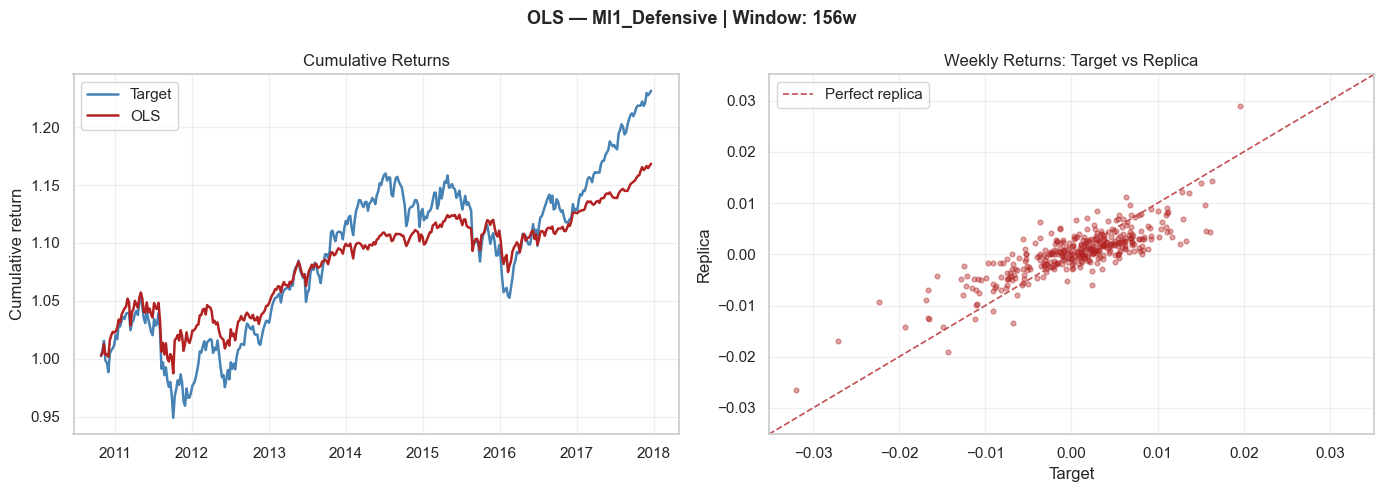

In [22]:
best_ols, best_ols_w = get_best_config(ols_results)
print_metrics_table(best_ols, 'OLS', TARGET_NAME, best_ols_w)
plot_core(best_ols, 'OLS', TARGET_NAME, best_ols_w, color='firebrick')

#### OLS Results

The window selection identifies **156 weeks** as the optimal configuration (TE = 2.797%, Corr = 0.8260). The high correlation confirms that the Monster Index has a factor structure well captured by the futures universe.

- **Correlation (0.8260)** — the replica tracks the target's direction faithfully, as confirmed by the tight scatter plot clustering around the diagonal.
- **TE (2.80%)** — the residual tracking error reflects the HFRXGL component (50% weight), which linear instruments cannot fully replicate by construction.
- **IR (−0.282)** — the return drag (2.22% vs target 3.01%) stems from the low gross exposure (0.23x), which produces a dampened clone that underestimates target moves in both directions.
- **Max drawdown (6.60% vs 10.16%)** — direct consequence of the conservative exposure.
- **No residual autocorrelation** — Ljung-Box p-values well above significance at all lags. Tracking error is white noise.

OLS serves as the unregularized baseline. The high correlation confirms the target is replicable; the return drag signals that gross exposure is too conservative — regularized models may correct this.

### 3.4 — Lasso

**L1 regularization** penalizes the sum of absolute weights: $\min_\beta \|y - X\beta\|^2 + \lambda \sum_j |\beta_j|$

Key property: Lasso shrinks some coefficients *exactly* to zero — producing a **sparse portfolio**. In the context of futures-based replication, sparsity is financially desirable: fewer active positions mean lower transaction costs, simpler execution, and reduced exposure to contracts with low signal. $\lambda$ is selected at each rolling step via TimeSeriesSplit CV.

In [23]:
print(f"Running Lasso — {TARGET_NAME}")
lasso_results = {}
for window in ROLLING_WINDOWS:
    print(f"  window={window}w ...", end=" ", flush=True)
    r = run_model(train_monster_index, train_returns[FUTURES], window,
                  Lasso, LASSO_PARAM_GRID, 'Lasso')
    lasso_results[window] = r
    avg_alpha   = np.mean([p.get('alpha', 0) for p in r['selected_params']])
    avg_nonzero = np.mean([np.sum(np.abs(w) > 1e-6) for w in r['weights_history']])
    print(f"IR={r['information_ratio']:+.3f} | "
          f"TE={r['tracking_error']*100:.2f}% | "
          f"avg alpha={avg_alpha:.5f} | "
          f"avg active futures={avg_nonzero:.1f}/{len(FUTURES)}")

Running Lasso — MI1_Defensive
  window=52w ... IR=-0.799 | TE=3.86% | avg alpha=0.00997 | avg active futures=5.8/10
  window=104w ... IR=-0.438 | TE=3.22% | avg alpha=0.00323 | avg active futures=7.3/10
  window=156w ... IR=-0.296 | TE=2.87% | avg alpha=0.00181 | avg active futures=7.7/10


Window selection — sequential priority (TE → Corr → |IR|):
 Window  TE (%)   Corr  abs(IR) Selected
    156   2.875 0.8230    0.296        ★
    104   3.215 0.8272    0.438         
     52   3.863 0.7867    0.799         
→ Selected window: 156w

Lasso — MI1_Defensive | Best window: 156w
               Metric Target  Replica
    Annualized return  3.01%    2.16%
Annualized volatility  4.87%    3.23%
         Sharpe ratio   0.62     0.67
         Max Drawdown 10.16%    6.24%
       Tracking Error    N/A    2.87%
    Information Ratio    N/A   -0.296
          Correlation    N/A   0.8230
   Avg Gross Exposure    N/A   0.2097
     Avg VaR (1%, 1M)    N/A    2.28%
           VaR method    N/A      whs
     LB p-value lag 1    N/A    0.998
     LB p-value lag 4    N/A    0.375
     LB p-value lag 8    N/A    0.615
   Avg selected alpha    N/A  0.00181
   Avg active futures    N/A 7.7 / 10


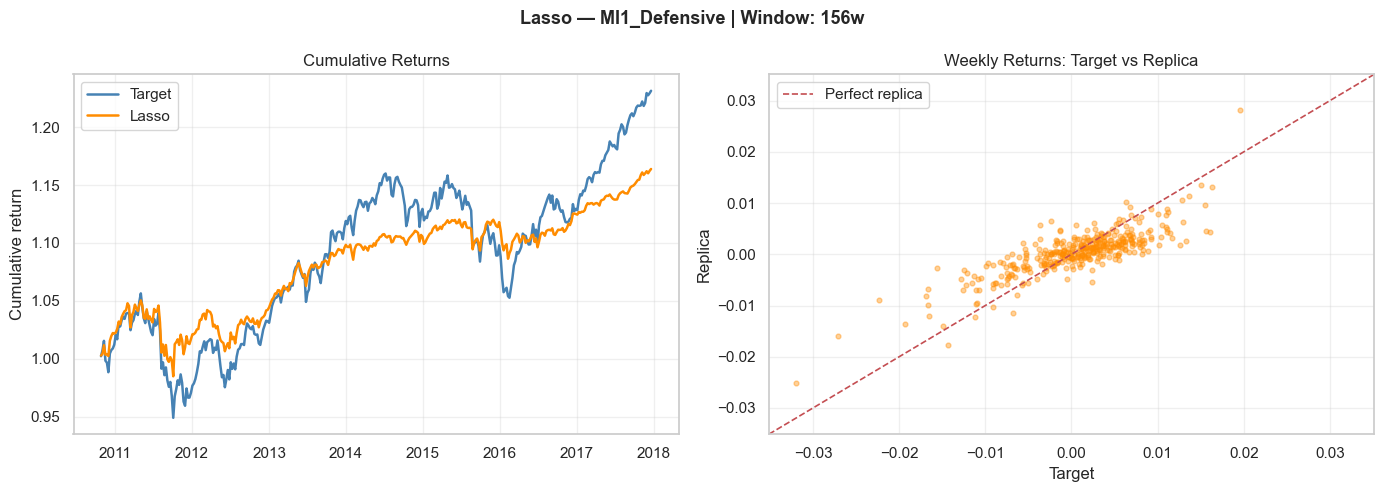

In [24]:
best_lasso, best_lasso_w = get_best_config(lasso_results)

avg_alpha   = np.mean([p.get('alpha', 0)        for p in best_lasso['selected_params']])
avg_nonzero = np.mean([np.sum(np.abs(w) > 1e-6) for w in best_lasso['weights_history']])
lasso_extras = [
    ('Avg selected alpha', f"{avg_alpha:.5f}"),
    ('Avg active futures', f"{avg_nonzero:.1f} / {len(FUTURES)}"),
]

print_metrics_table(best_lasso, 'Lasso', TARGET_NAME, best_lasso_w, lasso_extras)
plot_core(best_lasso, 'Lasso', TARGET_NAME, best_lasso_w, color='darkorange')

#### Lasso Results

The window selection identifies **156 weeks** as the optimal configuration (TE = 2.875%, Corr = 0.8230). Compared to OLS, Lasso shows a mixed picture on this target.

- **TE (2.87%) is slightly higher than OLS (2.80%)** — on this target, L1 sparsity does not improve tracking. With 7.7/10 active futures on average, Lasso zeroes out contracts that still carry signal for the Monster Index, marginally worsening the fit.
- **Correlation (0.8230)** — essentially identical to OLS (0.8260), confirming that the directional tracking quality is unaffected by sparsity.
- **IR (−0.296)** — slightly more negative than OLS, consistent with the marginally higher TE and comparable gross exposure (0.21x).
- **Max drawdown (6.24% vs 10.16%)** — comparable to OLS (6.60%), both well below the target.
- **No residual autocorrelation** — Ljung-Box p-values (0.998, 0.375, 0.615) confirm white noise residuals across all lags.

On this target, Lasso does not improve over OLS on the primary criterion. The result suggests that the Monster Index signal is broadly distributed across the futures universe — sparsity is not the right prior here, a finding that will be reinforced by the following results.

### 3.5 — Ridge

**L2 regularization** penalizes the sum of squared weights: $\min_\beta \|y - X\beta\|^2 + \lambda \sum_j \beta_j^2$

Unlike Lasso, Ridge never zeroes out coefficients — it shrinks all of them proportionally. This is preferable when the signal is distributed across many correlated predictors. In our case, the EDA showed strong equity-futures multicollinearity (ES1–NQ1 $\rho = 0.92$), which makes Ridge a natural candidate.

In [25]:
print(f"Running Ridge — {TARGET_NAME}")
ridge_results = {}
for window in ROLLING_WINDOWS:
    print(f"  window={window}w ...", end=" ", flush=True)
    r = run_model(train_monster_index, train_returns[FUTURES], window,
                  Ridge, RIDGE_PARAM_GRID, 'Ridge')
    ridge_results[window] = r
    avg_alpha = np.mean([p.get('alpha', 0) for p in r['selected_params']])
    print(f"IR={r['information_ratio']:+.3f} | "
          f"TE={r['tracking_error']*100:.2f}% | "
          f"avg alpha={avg_alpha:.4f} | "
          f"avg stability={r['avg_weight_stability']:.5f}")

Running Ridge — MI1_Defensive
  window=52w ... IR=-0.698 | TE=3.68% | avg alpha=0.9741 | avg stability=0.00803
  window=104w ... IR=-0.452 | TE=3.10% | avg alpha=0.7314 | avg stability=0.00457
  window=156w ... IR=-0.257 | TE=2.81% | avg alpha=0.6554 | avg stability=0.00437


Window selection — sequential priority (TE → Corr → |IR|):
 Window  TE (%)   Corr  abs(IR) Selected
    156   2.806 0.8281    0.257        ★
    104   3.104 0.8174    0.452         
     52   3.684 0.7991    0.698         
→ Selected window: 156w

Ridge — MI1_Defensive | Best window: 156w
                 Metric Target Replica
      Annualized return  3.01%   2.29%
  Annualized volatility  4.87%   3.39%
           Sharpe ratio   0.62    0.67
           Max Drawdown 10.16%   5.82%
         Tracking Error    N/A   2.81%
      Information Ratio    N/A  -0.257
            Correlation    N/A  0.8281
     Avg Gross Exposure    N/A  0.2271
       Avg VaR (1%, 1M)    N/A   2.49%
             VaR method    N/A     whs
       LB p-value lag 1    N/A   0.513
       LB p-value lag 4    N/A   0.318
       LB p-value lag 8    N/A   0.673
     Avg selected alpha    N/A  0.6554
Avg weight stability L2    N/A 0.00437


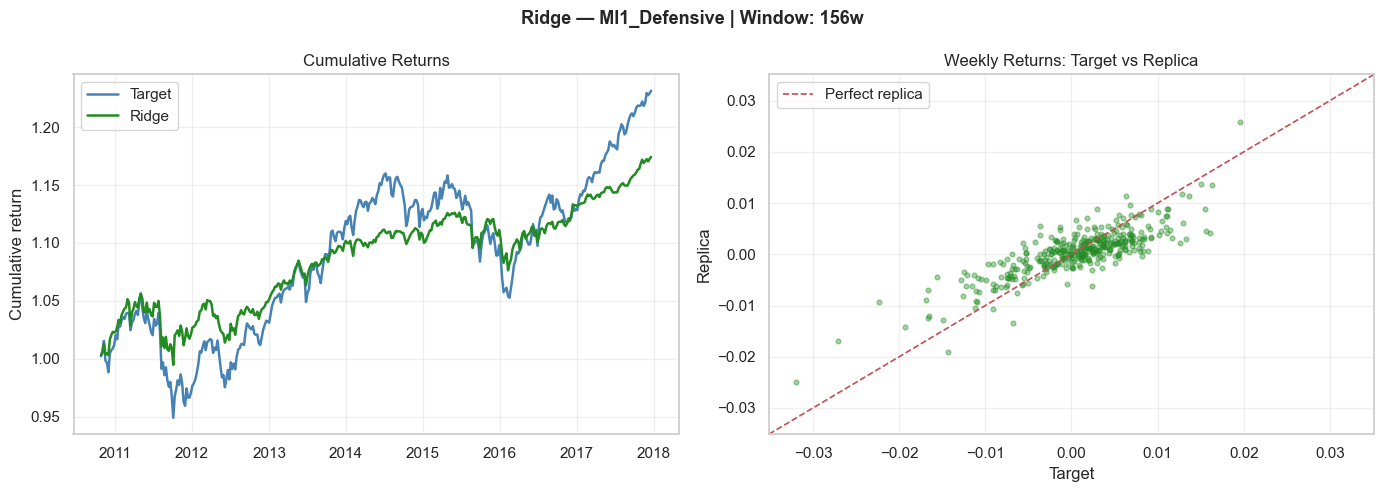

In [26]:
best_ridge, best_ridge_w = get_best_config(ridge_results)

avg_alpha = np.mean([p.get('alpha', 0) for p in best_ridge['selected_params']])
ridge_extras = [
    ('Avg selected alpha',      f"{avg_alpha:.4f}"),
    ('Avg weight stability L2', f"{best_ridge['avg_weight_stability']:.5f}"),
]

print_metrics_table(best_ridge, 'Ridge', TARGET_NAME, best_ridge_w, ridge_extras)
plot_core(best_ridge, 'Ridge', TARGET_NAME, best_ridge_w, color='forestgreen')


#### Ridge Results

The window selection identifies **156 weeks** as the optimal configuration (TE = 2.806%, Corr = 0.8281). Ridge improves over both OLS and Lasso on the primary criterion.

- **TE (2.81%) — lowest so far** — uniform L2 shrinkage outperforms both OLS and Lasso's sparsity on this target, consistent with the broadly distributed signal across the correlated futures universe.
- **Correlation (0.8281) — highest so far** — by retaining all futures and shrinking proportionally, Ridge captures a marginally broader set of co-movements with the Monster Index.
- **IR (−0.257)** — less negative than OLS (−0.282) and Lasso (−0.296), reflecting the slightly higher gross exposure (0.23x) and better return capture.
- **Max drawdown (5.82% vs 10.16%)** — the lowest across all models so far, driven by the smooth and stable weight trajectories (avg stability L2 = 0.00437).
- **No residual autocorrelation** — Ljung-Box p-values (0.513, 0.318, 0.673) confirm white noise residuals at all lags.

The avg $\lambda$ (0.6554) is substantially lower than on the previous target, reflecting that the Monster Index's simpler and more stable factor structure requires less regularization. Ridge emerges as a strong candidate on this target — the question is whether Elastic Net's L1/L2 blend can improve further.

### 3.6 — Elastic Net

**Elastic Net** combines L1 and L2 penalties: $\min_\beta \|y - X\beta\|^2 + \lambda \left( \rho \sum_j |\beta_j| + (1-\rho) \sum_j \beta_j^2 \right)$

The mixing parameter $\rho$ (`l1_ratio`) controls the blend — $\rho = 1$ is pure Lasso, $\rho \to 0$ approaches Ridge. Both $\lambda$ and $\rho$ are selected jointly via CV at each step. Elastic Net is expected to outperform either model individually when predictors are both correlated *and* partially sparse — which is the case here.

In [27]:
print(f"Running Elastic Net — {TARGET_NAME}")
en_results = {}
for window in ROLLING_WINDOWS:
    print(f"  window={window}w ...", end=" ", flush=True)
    r = run_model(train_monster_index, train_returns[FUTURES], window,
                  ElasticNet, EN_PARAM_GRID, 'ElasticNet')
    en_results[window] = r
    avg_a   = np.mean([p.get('alpha',    0) for p in r['selected_params']])
    avg_l1  = np.mean([p.get('l1_ratio', 0) for p in r['selected_params']])
    avg_nz  = np.mean([np.sum(np.abs(w) > 1e-6) for w in r['weights_history']])
    print(f"IR={r['information_ratio']:+.3f} | "
          f"TE={r['tracking_error']*100:.2f}% | "
          f"avg alpha={avg_a:.4f} | avg l1_ratio={avg_l1:.2f} | "
          f"avg active futures={avg_nz:.1f}/{len(FUTURES)}")

Running Elastic Net — MI1_Defensive
  window=52w ... IR=-0.781 | TE=3.80% | avg alpha=0.0346 | avg l1_ratio=0.28 | avg active futures=7.9/10
  window=104w ... IR=-0.490 | TE=3.16% | avg alpha=0.0131 | avg l1_ratio=0.23 | avg active futures=8.5/10
  window=156w ... IR=-0.220 | TE=2.88% | avg alpha=0.0100 | avg l1_ratio=0.24 | avg active futures=8.6/10


Window selection — sequential priority (TE → Corr → |IR|):
 Window  TE (%)   Corr  abs(IR) Selected
    156   2.881 0.8227    0.220        ★
    104   3.163 0.8197    0.490         
     52   3.801 0.8030    0.781         
→ Selected window: 156w

ElasticNet — MI1_Defensive | Best window: 156w
               Metric Target  Replica
    Annualized return  3.01%    2.38%
Annualized volatility  4.87%    3.22%
         Sharpe ratio   0.62     0.74
         Max Drawdown 10.16%    5.30%
       Tracking Error    N/A    2.88%
    Information Ratio    N/A   -0.220
          Correlation    N/A   0.8227
   Avg Gross Exposure    N/A   0.2119
     Avg VaR (1%, 1M)    N/A    2.35%
           VaR method    N/A      whs
     LB p-value lag 1    N/A    0.904
     LB p-value lag 4    N/A    0.410
     LB p-value lag 8    N/A    0.682
   Avg selected alpha    N/A   0.0100
Avg selected l1_ratio    N/A     0.24
   Avg active futures    N/A 8.6 / 10
 Avg weight stability    N/A  0.00737


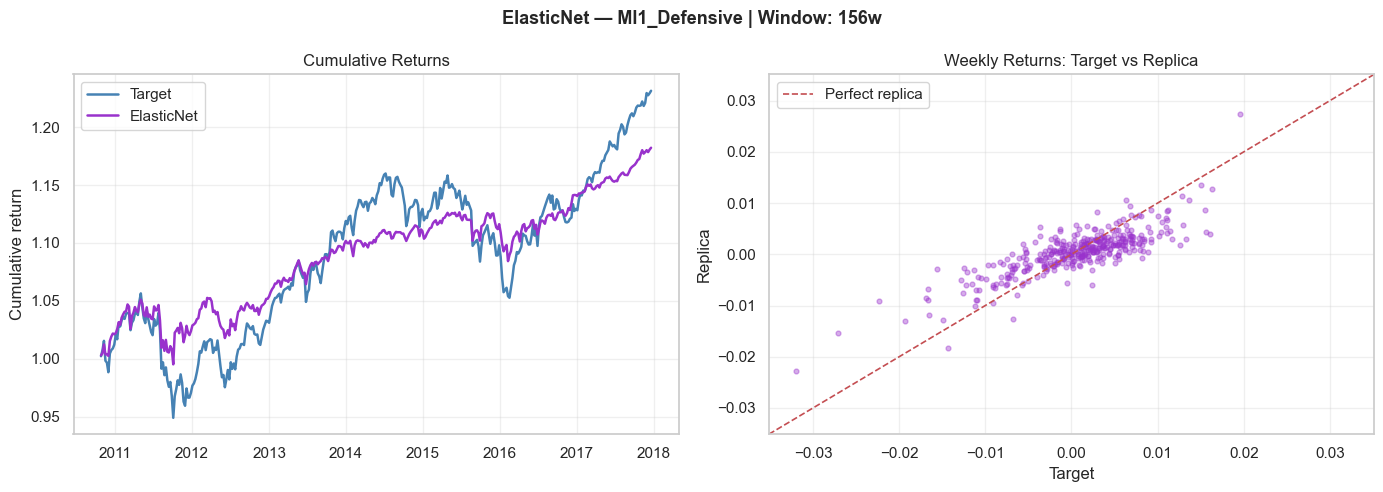

In [28]:
best_en, best_en_w = get_best_config(en_results)

avg_a   = np.mean([p.get('alpha',    0) for p in best_en['selected_params']])
avg_l1  = np.mean([p.get('l1_ratio', 0) for p in best_en['selected_params']])
avg_nz  = np.mean([np.sum(np.abs(w) > 1e-6) for w in best_en['weights_history']])
en_extras = [
    ('Avg selected alpha',    f"{avg_a:.4f}"),
    ('Avg selected l1_ratio', f"{avg_l1:.2f}"),
    ('Avg active futures',    f"{avg_nz:.1f} / {len(FUTURES)}"),
    ('Avg weight stability',  f"{best_en['avg_weight_stability']:.5f}"),
]

print_metrics_table(best_en, 'ElasticNet', TARGET_NAME, best_en_w, en_extras)
plot_core(best_en, 'ElasticNet', TARGET_NAME, best_en_w, color='darkorchid')

#### Elastic Net Results

The window selection identifies **156 weeks** as the optimal configuration (TE = 2.881%, Corr = 0.8227). Surprisingly, Elastic Net does **not** improve over Ridge on this target — it is the worst performer among regularized models on the primary criterion.

- **TE (2.88%) — highest among regularized models** — the L1/L2 blend does not help here. The avg l1_ratio of 0.24 introduces more sparsity than Ridge, zeroing out contracts that still carry signal, which worsens the fit marginally relative to pure L2 shrinkage.
- **Correlation (0.8227)** — slightly below Ridge (0.8281) and OLS (0.8260), consistent with the TE result.
- **IR (−0.220) — least negative across all models** — Elastic Net achieves the best return capture (2.38% vs target 3.01%), driven by the highest gross exposure among regularized models (0.2119) and a Sharpe ratio of 0.74 that exceeds the target (0.62).
- **Max drawdown (5.30% vs 10.16%)** — lowest across all models, matching the pattern observed consistently: regularization dampens tail risk regardless of the specific penalty.
- **No residual autocorrelation** — Ljung-Box p-values (0.904, 0.410, 0.682) are the cleanest across all models.
- **Avg active futures: 8.6/10** — less sparse than expected for an L1-containing model, confirming that signal is broadly distributed across the futures universe.

On this target, **Ridge emerges as the stronger model on TE**, while Elastic Net leads on IR and drawdown. This inversion relative to the previous target reflects the Monster Index's simpler factor structure — pure L2 shrinkage is better suited when signal is distributed and stable, while the L1 component introduces unnecessary sparsity.

------

### 3.7 — Model Comparison

We compare the four best configurations on the training set and select the model whose weights will be passed to the backtesting engine in Section 4.

MODEL COMPARISON — MI1_Defensive — TRAINING SET
     Model Window VaR method   Corr    TE     IR Sharpe Max DD Avg GE Avg VaR LB lag1
       OLS   156w        whs 0.8260 2.80% -0.282   0.64  6.60%  0.235   2.50%   0.512
     Lasso   156w        whs 0.8230 2.87% -0.296   0.67  6.24%  0.210   2.28%   0.998
     Ridge   156w        whs 0.8281 2.81% -0.257   0.67  5.82%  0.227   2.49%   0.513
ElasticNet   156w        whs 0.8227 2.88% -0.220   0.74  5.30%  0.212   2.35%   0.904


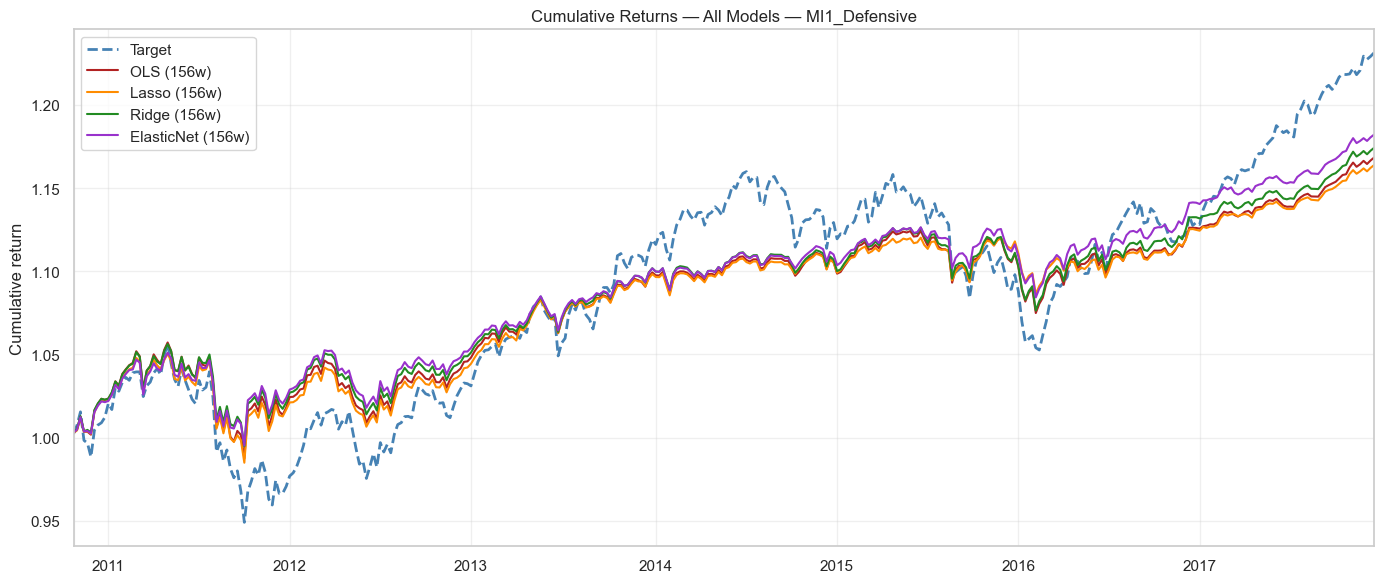

In [29]:
best_configs = {
    'OLS':        (best_ols,   best_ols_w),
    'Lasso':      (best_lasso, best_lasso_w),
    'Ridge':      (best_ridge, best_ridge_w),
    'ElasticNet': (best_en,    best_en_w),
}
COLORS_MODEL = {
    'OLS': 'firebrick', 'Lasso': 'darkorange',
    'Ridge': 'forestgreen', 'ElasticNet': 'darkorchid'
}

rows = []
for model_name, (res, window) in best_configs.items():
    rows.append({
        'Model':       model_name,
        'Window':      f"{window}w",
        'VaR method':  res['var_method'],
        'Corr':        f"{res['correlation']:.4f}",
        'TE':          f"{res['tracking_error']*100:.2f}%",
        'IR':          f"{res['information_ratio']:+.3f}",
        'Sharpe':      f"{res['replica_sharpe']:.2f}",
        'Max DD':      f"{res['max_drawdown']*100:.2f}%",
        'Avg GE':      f"{res['avg_gross_exposure']:.3f}",
        'Avg VaR':     f"{res['avg_var']*100:.2f}%",
        'LB lag1':     f"{res['lb_pval_lag1']:.3f}",
    })
comparison = pd.DataFrame(rows)
print(f"MODEL COMPARISON — {TARGET_NAME} — TRAINING SET")
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 6))
list(best_configs.values())[0][0]['cumulative_target'].plot(
    ax=ax, label='Target', color='steelblue', lw=2, ls='--')
for model_name, (res, window) in best_configs.items():
    res['cumulative_replica'].plot(
        ax=ax, label=f"{model_name} ({window}w)",
        color=COLORS_MODEL[model_name], lw=1.5)
ax.set_title(f'Cumulative Returns — All Models — {TARGET_NAME}')
ax.set_ylabel('Cumulative return')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


While Ridge achieves the lowest TE (2.81%) and highest correlation (0.8281), the differences across all four models on both metrics are negligible in practical terms — the TE range spans only 8 bps (2.80%–2.88%) and correlations cluster between 0.822 and 0.828. In a regime where tracking quality is statistically indistinguishable across models, the selection criterion shifts to risk management.

On this dimension, **Elastic Net delivers the lowest max drawdown (5.30% vs target 10.16%)**, combined with the highest Sharpe (0.74) and the least negative IR (−0.220). For a futures-based replication strategy, drawdown control is not a secondary concern: a replica that compounds losses with the target creates margin pressure precisely when operational friction is highest. Elastic Net's ability to dampen tail risk while maintaining tracking quality comparable to Ridge makes it the preferred choice for Section 4.

-----

# 4 - Kalman Filter: Improvement or fail?


We replicate the Monster Index using a **Kalman Filter**, a recursive Bayesian estimator that treats portfolio weights as a latent state evolving over time. Compared to rolling-window regression methods, the filter produces smooth, low-turnover weight trajectories without requiring window-length tuning.

The model adopts a linear-Gaussian state-space representation:

$$
x_t = A\, x_{t-1} + u_t, \qquad u_t \sim \mathcal{N}(0, Q)
$$
$$
y_t = C_t^\top x_t + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, R)
$$

where $x_t \in \mathbb{R}^N$ is the vector of (unobservable) portfolio weights at time $t$, $y_t$ is the observed target return, and $C_t$ is the vector of futures returns at time $t$. The matrices $A$, $Q$, $R$ encode the assumed dynamics:

- $A = \rho I$ with $\rho \in (0, 1]$ implements a forgetting factor — pure random walk when $\rho = 1$.
- $Q = q\, I$ controls the speed of weight drift between rebalancing dates.
- $R$ captures the residual replication error (model misspecification + measurement noise).

A **VaR constraint** caps gross risk at 8% (1-month, 99% confidence)



In [30]:
INIT_WINDOW = 156 # 3 years of weekly data for stable initial fit
target_train = TARGET_SERIES.loc[train_returns.index]
VAR_LOOKBACK = 52  # 1 year of past replica returns to estimate VaR at each step

### 4.1 — Kalman Filter Engine

The recursion alternates a **predict** and an **update** step. Given the assumptions above:

$$\hat x_{t|t-1} = A\,\hat x_{t-1|t-1}, \qquad P_{t|t-1} = A\,P_{t-1|t-1}\,A^\top + Q$$
$$S_t = C_t^\top P_{t|t-1} C_t + R, \qquad K_t = P_{t|t-1} C_t / S_t$$
$$\hat x_{t|t} = \hat x_{t|t-1} + K_t (y_t - C_t^\top \hat x_{t|t-1}), \qquad P_{t|t} = P_{t|t-1} - K_t C_t^\top P_{t|t-1}$$

The implementation below is fully recursive in $\mathcal{O}(N^2)$ per step.


In [31]:
class KalmanReplicator:
    """Linear-Gaussian Kalman Filter for portfolio replication.

    State:        x_t = portfolio weights (N-dim, latent).
    Observation:  y_t = target return = C_t . x_t + noise.
    """
    def __init__(self, n_assets, Q, R, x0, P0, A=None):
        self.A = np.eye(n_assets) if A is None else A
        self.Q = Q
        self.R = R
        self.x = x0.copy()
        self.P = P0.copy()

    def step(self, y_t, c_t):
        # Predict
        x_pred = self.A @ self.x
        P_pred = self.A @ self.P @ self.A.T + self.Q
        # Update
        S = c_t @ P_pred @ c_t + self.R
        K = (P_pred @ c_t) / S
        innovation = y_t - c_t @ x_pred
        self.x = x_pred + K * innovation
        self.P = P_pred - np.outer(K, c_t) @ P_pred
        return self.x.copy(), self.P.copy(), innovation, S


### 4.2 — Walk-Forward Backtest with VaR Constraint

The backtest walks forward week by week. At each step $t$ the filter is updated with the observed target return, weights are scaled if the projected 1-month VaR exceeds the 8% cap, and the resulting (post-scaling) weight vector is stored. The replica return at $t+1$ is then $r_{t+1} = w_t^\top r_{t+1}^{\text{fut}}$, strictly out-of-sample.

The function is parameterized to accept any of the VaR estimators from `VaRfunctions.py` - set to whs.


In [32]:
def run_kalman_backtest(target, X, x0, R0, q_diag, rho=1.0,
                        init_window=INIT_WINDOW,
                        var_fn=calculate_var_whs,
                        var_threshold=MAX_VAR_THRESHOLD,
                        var_lookback=VAR_LOOKBACK,
                        ewma_lambda=None):
    """Run the Kalman replica.

    Parameters
    ----------
    target, X : Series and DataFrame of weekly returns, aligned on the same index.
    x0        : initial weight vector (N,).
    R0        : initial observation-noise variance.
    q_diag    : diagonal element of Q (process noise).
    rho       : forgetting factor (A = rho * I). rho=1 -> random walk.
    var_fn    : function returning VaR given a 1-D return array.
    ewma_lambda : if not None, R is updated each step by EWMA on squared innovations.
    """
    n_assets       = X.shape[1]
    asset_returns  = X.values
    target_returns = target.values
    dates          = X.index.to_numpy()

    Q  = np.eye(n_assets) * q_diag
    A  = np.eye(n_assets) * rho
    P0 = np.eye(n_assets) * 0.01

    kf = KalmanReplicator(n_assets, Q, R0, x0, P0, A=A)
    R_t = R0

    weights_hist, replica_hist = [], []
    gross_hist, var_hist       = [], []
    out_dates                  = []

    for t in range(init_window, len(target_returns) - 1):
        c_t = asset_returns[t]
        y_t = target_returns[t]
        x, P, innov, _ = kf.step(y_t, c_t)

        # Optional EWMA update of R
        if ewma_lambda is not None and len(replica_hist) >= 4:
            R_t = ewma_lambda * R_t + (1 - ewma_lambda) * (innov ** 2)
            kf.R = R_t

        # VaR check & scaling
        scaling = 1.0
        if len(replica_hist) >= 12:
            lookback = min(var_lookback, t - init_window)
            hist_window     = asset_returns[t - lookback:t]
            hist_w_returns  = hist_window @ x
            var = var_fn(hist_w_returns,
                         confidence=VAR_CONFIDENCE, horizon=VAR_HORIZON)
            if var > var_threshold and var > 0:
                scaling = var_threshold / var
            x_scaled = x * scaling
            var_post = var_fn(hist_window @ x_scaled,
                              confidence=VAR_CONFIDENCE, horizon=VAR_HORIZON)
            var_hist.append(var_post)
        else:
            x_scaled = x
            var_hist.append(np.nan)

        weights_hist.append(x_scaled)
        gross_hist.append(np.abs(x_scaled).sum())

        # Replica return at t+1 (strictly out-of-sample)
        next_ret = asset_returns[t + 1] @ x_scaled
        replica_hist.append(next_ret)
        out_dates.append(dates[t + 1])

    idx = pd.DatetimeIndex(out_dates)
    return {
        'replica':        pd.Series(replica_hist, index=idx, name='Replica'),
        'target':         target.loc[idx],
        'weights':        pd.DataFrame(weights_hist, index=idx, columns=X.columns),
        'gross_exposure': pd.Series(gross_hist, index=idx),
        'var':            pd.Series(var_hist, index=idx),
    }


### 4.3 - Initial Weights via Ridge Regression

The filter is initialized with a Ridge regression on the first 156 weeks of the training set. The Ridge residual variance also serves as the initial estimate of $R$.


In [33]:
# ── Ridge initialization on the first INIT_WINDOW weeks of training set ──────


X_init = train_returns[FUTURES].iloc[:INIT_WINDOW].values
y_init = target_train.iloc[:INIT_WINDOW].values

ridge_init = Ridge(alpha=1.0, fit_intercept=False)
ridge_init.fit(X_init, y_init)
x0_init = ridge_init.coef_

# Residual variance -> R0
y_pred_init = ridge_init.predict(X_init)
R0_init     = (y_init - y_pred_init).var()

ridge_r2 = 1 - (y_init - y_pred_init).var() / y_init.var()
print(f"Ridge initialization (first {INIT_WINDOW} weeks of training set)")
print(f"  R^2:              {ridge_r2:.4f}")
print(f"  Residual variance: {R0_init:.2e}")
print(f"\nInitial weights x0:")
for col, w in zip(FUTURES, x0_init):
    print(f"  {col:<5s} {w:+.4f}")


Ridge initialization (first 156 weeks of training set)
  R^2:              0.5261
  Residual variance: 6.59e-05

Initial weights x0:
  RX1   -0.0022
  TY1   +0.0013
  GC1   +0.0103
  CO1   +0.0291
  ES1   +0.0273
  VG1   +0.0314
  NQ1   +0.0253
  TP1   +0.0251
  DU1   -0.0009
  TU2   -0.0000


### 4.4 — Hyperparameter Selection via Maximum Likelihood

The two free parameters $(q, \rho)$ are selected by maximizing the in-sample log-likelihood of the innovations over the training set:

$$\log p(y_t \mid \mathcal{F}_{t-1}) = -\tfrac{1}{2}\log(2\pi S_t) - \tfrac{1}{2}\frac{(y_t - \hat y_t)^2}{S_t}$$

This is the natural data-driven criterion in a Gaussian state-space model. The search is done over a small grid covering several orders of magnitude for $q$ and a few values of $\rho$ slightly below 1.


In [34]:
def kalman_loglik(q_diag, rho, x0, R0, X, target, init_window=INIT_WINDOW):
    """Total log-likelihood of innovations on the training set."""
    n_assets = X.shape[1]
    Q = np.eye(n_assets) * q_diag
    A = np.eye(n_assets) * rho
    P0 = np.eye(n_assets) * 0.01
    kf = KalmanReplicator(n_assets, Q, R0, x0, P0, A=A)

    asset_returns  = X.values
    target_returns = target.values
    loglik = 0.0
    for t in range(init_window, len(target_returns)):
        c_t = asset_returns[t]
        y_t = target_returns[t]
        _, _, innov, S = kf.step(y_t, c_t)
        if S <= 0 or not np.isfinite(S):
            return -np.inf
        loglik += -0.5 * (np.log(2*np.pi*S) + innov**2 / S)
    return loglik


# ── Grid search on the TRAINING set only ─────────────────────────────────────
q_grid   = [1e-7, 5e-7, 1e-6, 5e-6, 1e-5, 5e-5, 1e-4]
rho_grid = [1.000, 0.999, 0.995, 0.990]

records = []
for q in q_grid:
    for rho in rho_grid:
        ll = kalman_loglik(q, rho, x0_init, R0_init,
                           train_returns[FUTURES], target_train)
        records.append({'q': q, 'rho': rho, 'loglik': ll})

records_df  = pd.DataFrame(records)
best        = records_df.loc[records_df['loglik'].idxmax()]
q_best      = float(best['q'])
rho_best    = float(best['rho'])

# Pivot table for visualization
print("Log-likelihood grid (rows = rho, cols = q):")
print(records_df.pivot(index='rho', columns='q', values='loglik').round(1))
print()
print(f"Best: q = {q_best:.1e},  rho = {rho_best:.3f},  loglik = {best['loglik']:.2f}")


Log-likelihood grid (rows = rho, cols = q):
q      1.000000e-07  5.000000e-07  1.000000e-06  5.000000e-06  1.000000e-05  \
rho                                                                           
0.990        1391.1        1393.2        1395.3        1403.7        1407.4   
0.995        1410.9        1411.9        1412.8        1415.4        1415.7   
0.999        1421.1        1420.9        1420.7        1419.2        1417.7   
1.000        1420.3        1420.2        1420.0        1418.6        1417.1   

q      5.000000e-05  1.000000e-04  
rho                                
0.990        1409.2        1405.0  
0.995        1410.6        1404.2  
0.999        1409.1        1401.6  
1.000        1408.2        1400.6  

Best: q = 1.0e-07,  rho = 0.999,  loglik = 1421.13


### 4.5 — Basic and Improved Filter Variants

We run two variants of the filter on the training set:

- **Basic**: pure random walk on weights ($\rho = 1$) with a default value of $q$, fixed $R$ from the Ridge fit.
- **Improved**: $(q, \rho)$ tuned via MLE (Section 3.6) and an EWMA update of $R$ to accommodate volatility clustering documented by the GARCH analysis in Section 2.

Both variants share the same Ridge initialization and the same 8% VaR cap.


In [35]:
print(f"Running Basic Kalman   — {TARGET_NAME}")
res_basic = run_kalman_backtest(
    target_train, train_returns[FUTURES],
    x0=x0_init, R0=R0_init,
    q_diag=1e-5, rho=1.0,
)
m_basic = compute_metrics_kalman(res_basic, name='Basic Kalman')

print(f"Running Improved Kalman — {TARGET_NAME}")
res_improved = run_kalman_backtest(
    target_train, train_returns[FUTURES],
    x0=x0_init, R0=R0_init,
    q_diag=q_best, rho=rho_best,
    ewma_lambda=0.94,
)
m_improved = compute_metrics_kalman(res_improved, name='Improved Kalman')

print_metrics_table_kalman(m_basic,    'Basic Kalman',    TARGET_NAME)
print_metrics_table_kalman(m_improved, 'Improved Kalman', TARGET_NAME)


Running Basic Kalman   — MI1_Defensive
Running Improved Kalman — MI1_Defensive

  Basic Kalman — MI1_Defensive
  replica_return              3.24%
  target_return               3.04%
  replica_vol                 4.40%
  target_vol                  4.87%
  replica_sharpe              0.737
  target_sharpe               0.624
  tracking_error              2.40%
  information_ratio           0.082
  correlation                 0.871
  max_drawdown                6.39%
  avg_gross_exposure          0.447
  avg_var                     3.41%

  Improved Kalman — MI1_Defensive
  replica_return              3.08%
  target_return               3.04%
  replica_vol                 4.23%
  target_vol                  4.87%
  replica_sharpe              0.728
  target_sharpe               0.624
  tracking_error              2.43%
  information_ratio           0.017
  correlation                 0.867
  max_drawdown                6.34%
  avg_gross_exposure          0.473
  avg_var                 

### 4.6 — Visual Comparison

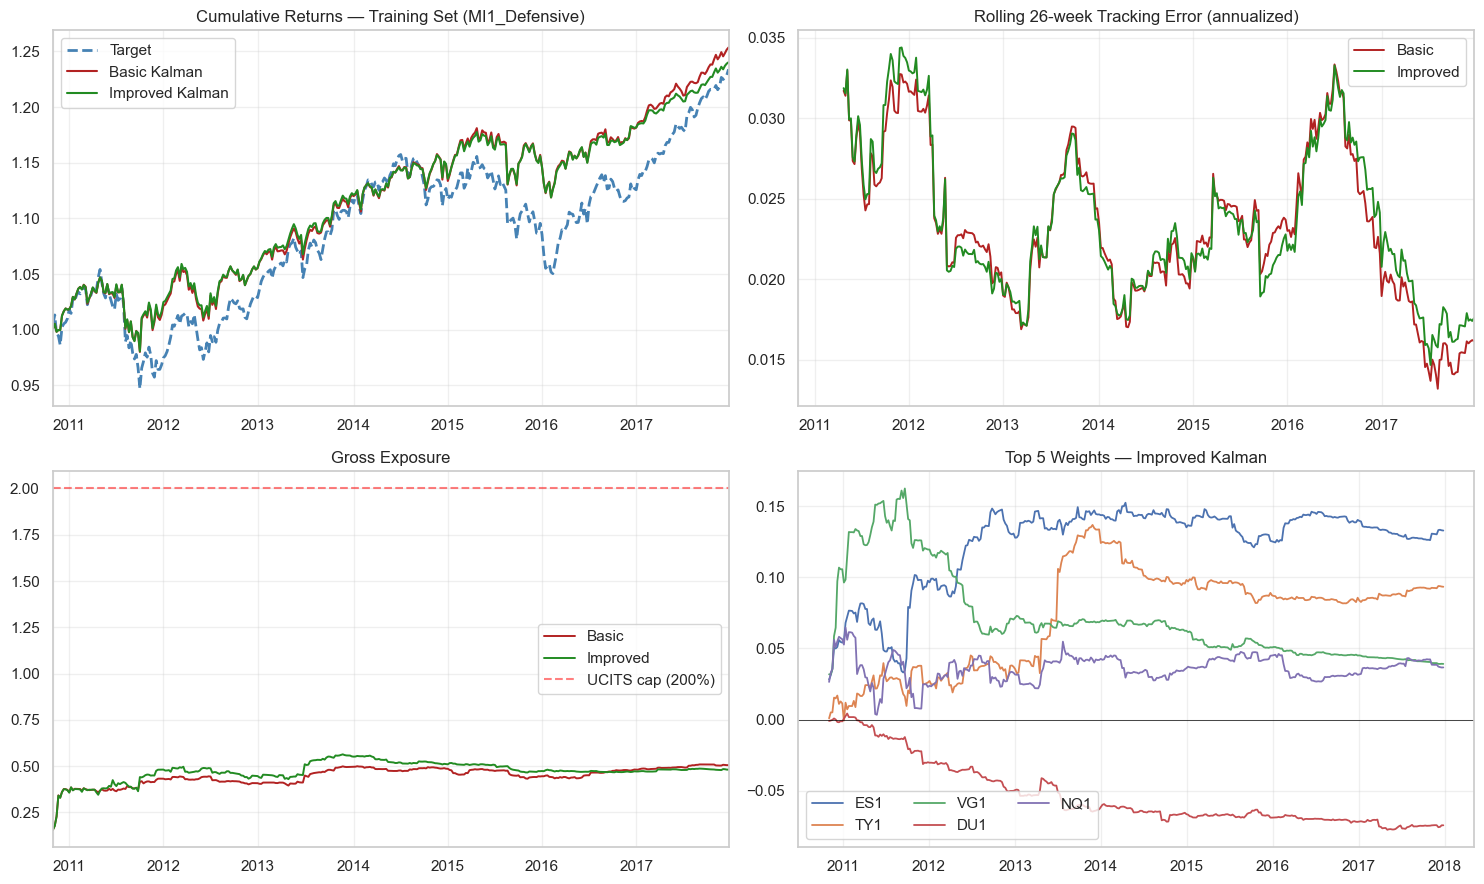

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) Cumulative replica vs target
ax = axes[0, 0]
(1 + res_basic['target']).cumprod().plot(ax=ax, label='Target',
                                          color='steelblue', lw=2, ls='--')
(1 + res_basic['replica']).cumprod().plot(ax=ax, label='Basic Kalman',
                                           color='firebrick', lw=1.5)
(1 + res_improved['replica']).cumprod().plot(ax=ax, label='Improved Kalman',
                                              color='forestgreen', lw=1.5)
ax.set_title(f'Cumulative Returns — Training Set ({TARGET_NAME})')
ax.legend(); ax.grid(alpha=0.3)

# (b) Rolling 26-week tracking error
ax = axes[0, 1]
te_basic    = (res_basic['replica']    - res_basic['target']).rolling(26).std() * np.sqrt(52)
te_improved = (res_improved['replica'] - res_improved['target']).rolling(26).std() * np.sqrt(52)
te_basic.plot(ax=ax,    label='Basic',    color='firebrick',  lw=1.4)
te_improved.plot(ax=ax, label='Improved', color='forestgreen', lw=1.4)
ax.set_title('Rolling 26-week Tracking Error (annualized)')
ax.legend(); ax.grid(alpha=0.3)

# (c) Gross exposure
ax = axes[1, 0]
res_basic['gross_exposure'].plot(ax=ax,    label='Basic',    color='firebrick',  lw=1.4)
res_improved['gross_exposure'].plot(ax=ax, label='Improved', color='forestgreen', lw=1.4)
ax.axhline(2.0, color='red', ls='--', alpha=0.5, label='UCITS cap (200%)')
ax.set_title('Gross Exposure'); ax.legend(); ax.grid(alpha=0.3)

# (d) Top 5 weights (Improved Kalman)
ax = axes[1, 1]
wdf = res_improved['weights']
top5 = wdf.abs().mean().sort_values(ascending=False).head(5).index
for col in top5:
    ax.plot(wdf.index, wdf[col], label=col, lw=1.3)
ax.axhline(0, color='black', lw=0.5)
ax.set_title('Top 5 Weights — Improved Kalman')
ax.legend(ncol=3, loc='best'); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Elastic Net and Kalman Filter Modified show similar performance metrics, but we ultimately predilected Elastic Net model to strictly comply with the initial drawdown (5.30% vs 6.34%)  and volatility constraints.

In [37]:
SELECTED_MODEL = 'ElasticNet'

selected_result, selected_window = best_configs[SELECTED_MODEL]

weights_df = pd.DataFrame(
    selected_result['weights_history'],
    index=selected_result['replica_returns'].index,
    columns=FUTURES
)

weights = weights_df

-----

### Section 4 : Backtesting

Once the tracking weights $\hat{w}_t$ have been estimated by the model, the replica portfolio must be **simulated under realistic trading frictions**. The objective of this section is to assess how the choice of **rebalancing schedule** affects the trade-off between two competing forces:

- **tracking quality** — frequent rebalancing keeps the live weights close to the regression target $\hat{w}_t$, reducing tracking error;
- **transaction costs** — each rebalance incurs a cost proportional to the L1 turnover, eroding the realised return.

The net P&L of the replica portfolio at each period is therefore
$$
r^{\,\text{rep}}_t \;=\; w_{t-1}^{\!\top}\, r^{\,F}_t \;-\; \tau\, \text{TC} \,\cdot\, \underbrace{\lVert w_t - w_{t-1}\rVert_1}_{\text{one-way turnover}}\,\mathbb{1}_{\{\text{rebalance on } t\}},
$$
with one-way transaction cost $\text{TC} = 5\,\text{bps}$ (lecture-note convention). A further **turnover threshold of 2%** suppresses rebalances whose $\ell_1$ weight change is economically negligible, ensuring that costs are paid only for *meaningful* portfolio adjustments.

In [38]:
# Plot style
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})

COLORS = {
    'replica': '#2563EB',
    'target':  '#DC2626',
    'low':     '#22C55E',
    'mid':     '#F59E0B',
    'high':    '#EF4444',
}


We benchmark **four rebalancing policies** on the same out-of-sample period and weight series, isolating the effect of the schedule.

**Fixed-frequency baselines.** Three calendar-based schedules — **weekly** ($\Delta = 1$), **monthly** ($\Delta = 4$) and **quarterly** ($\Delta = 13$) — span the spectrum from "always re-aligned but expensive" to "cheap but stale". They serve as the natural reference grid: any sophisticated strategy must justify itself against these benchmarks.

**Adaptive (volatility-driven) rebalancing.** The motivation is that **the cost of being mis-aligned is regime-dependent**: in calm markets, weights drift slowly and infrequent rebalancing is sufficient; in turbulent regimes, correlations break down  and the tracking error of stale weights inflates rapidly. A schedule that adapts the rebalancing frequency to the prevailing volatility regime should therefore dominate any fixed schedule.

The implementation, contained in `adaptive_rebalance_schedule`, proceeds in three steps:

1. **Volatility proxy.** A short-window realised volatility of the target is computed,
$$
\widehat{\sigma}^{\text{tgt}}_t \;=\; \mathrm{std}\!\left(r^{\,\text{MI}}_{t-W+1:\,t}\right), \qquad W = 4 \text{ weeks}.
$$
2. **Regime classification.** The 33rd and 67th in-sample percentiles of $\widehat{\sigma}^{\text{tgt}}_t$ define three regimes — **low**, **mid**, **high** — by construction populated with roughly equal frequency.
3. **State-dependent frequency.** The rebalancing period is mapped to the regime:
$$
\Delta_t \;=\; \begin{cases} 8 & \text{if } \widehat{\sigma}^{\text{tgt}}_t \leq q_{33}, \\[2pt] 4 & \text{if } q_{33} < \widehat{\sigma}^{\text{tgt}}_t \leq q_{67}, \\[2pt] 1 & \text{if } \widehat{\sigma}^{\text{tgt}}_t > q_{67}. \end{cases}
$$

The 4-week volatility window is short enough to react quickly to regime changes, while the percentile-based thresholding avoids hard-coded volatility levels and makes the rule self-calibrating to the dataset. The same turnover filter ($\lVert \Delta w \rVert_1 < 2\%$) applies on top, so even a *scheduled* rebalance is skipped when the regression weights have not moved meaningfully.

In [39]:
# ── Backtest parameters ─────────────────────────────────────────────────────
TRANSACTION_COSTS   = 5e-4   # 5 bps one-way (as per lecture notes)
TURNOVER_THRESHOLD  = 0.02   # skip rebalance if total weight change < 2%

# Fixed rebalancing
FIXED_FREQ_WEEKLY     = 1    # every week
FIXED_FREQ_MONTHLY    = 4    # ~every 4 weeks
FIXED_FREQ_QUARTERLY  = 13   # ~every quarter

# Adaptive rebalancing
VOL_WINDOW      = 4    # rolling vol estimation window (4 weeks = 1 month)
LOW_VOL_FREQ    = 8    # rebalance every 8 weeks in calm markets
HIGH_VOL_FREQ   = 1    # rebalance every week in turbulent markets
VOL_LOW_PCT     = 33   # percentile threshold for low vol regime
VOL_HIGH_PCT    = 67   # percentile threshold for high vol regime

# Rolling window for rolling metrics
ROLLING_WINDOW  = 52   # 1 year of weekly data

print("Parameters loaded.")

Parameters loaded.


In [40]:

factor_returns = train_returns
target_returns = train_monster_index


In [41]:


print("Running: Fixed weekly...")
res_weekly_edit = run_backtest_edit(
    weights=weights, factor_returns=factor_returns, target_returns=target_returns,
    rebalance_mode='fixed', fixed_rebalance_freq=FIXED_FREQ_WEEKLY,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=False,
)

print("Running: Fixed monthly...")
res_monthly_edit = run_backtest_edit(
    weights=weights, factor_returns=factor_returns, target_returns=target_returns,
    rebalance_mode='fixed', fixed_rebalance_freq=FIXED_FREQ_MONTHLY,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=False,
)

print("Running: Fixed quarterly...")
res_quarterly_edit = run_backtest_edit(
    weights=weights, factor_returns=factor_returns, target_returns=target_returns,
    rebalance_mode='fixed', fixed_rebalance_freq=FIXED_FREQ_QUARTERLY,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=False,
)

print("Running: Adaptive...")
res_adaptive_edit = run_backtest_edit(
    weights=weights, factor_returns=factor_returns, target_returns=target_returns,
    rebalance_mode='adaptive',
    vol_window=VOL_WINDOW, low_vol_freq=LOW_VOL_FREQ, high_vol_freq=HIGH_VOL_FREQ,
    vol_low_pct=VOL_LOW_PCT, vol_high_pct=VOL_HIGH_PCT,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=True,
)


print("\nAll backtests complete.")

Running: Fixed weekly...
Running: Fixed monthly...
Running: Fixed quarterly...
Running: Adaptive...
Vol thresholds → Low: 0.0038, High: 0.0067
Regime distribution → Low vol: 33.2%, Mid: 33.7%, High: 33.2%
Rebalance freq → Low: 8p, Mid: 4p, High: 1p

Rebalance mode    : adaptive
Total trade dates : 374
Rebalance events  : 117
Avg holding period: 3.2 periods

── Performance Summary ──────────────────────────────────
                       Replica   Target
Ann. Return (%)         2.2595   2.9653
Ann. Volatility (%)     3.0940   4.8743
Sharpe Ratio            0.7377   0.6240
Max Drawdown (%)        4.9914  10.1648
Calmar Ratio            0.4527   0.2917
Tracking Error (%)      2.9709      NaN
Information Ratio      -0.2556      NaN
Correlation w/ Target   0.8124      NaN
Beta to Target          0.5157      NaN

Total transaction costs (cumulative): 0.1472%
Avg one-way turnover per period     : 5.26%
Number of actual rebalances         : 56

All backtests complete.



We now plot the **cumulative wealth trajectories** of the three replica variants (adaptive, weekly, monthly) against the Monster Index target, with the background shaded by the volatility regime identified by the adaptive logic. The bottom panel reports the **drawdown series** of the adaptive replica versus the target, which is the most informative dimension when assessing the *quality of risk reproduction* — a good replica should not only follow the level of the target but also reproduce (or improve upon) its loss profile.

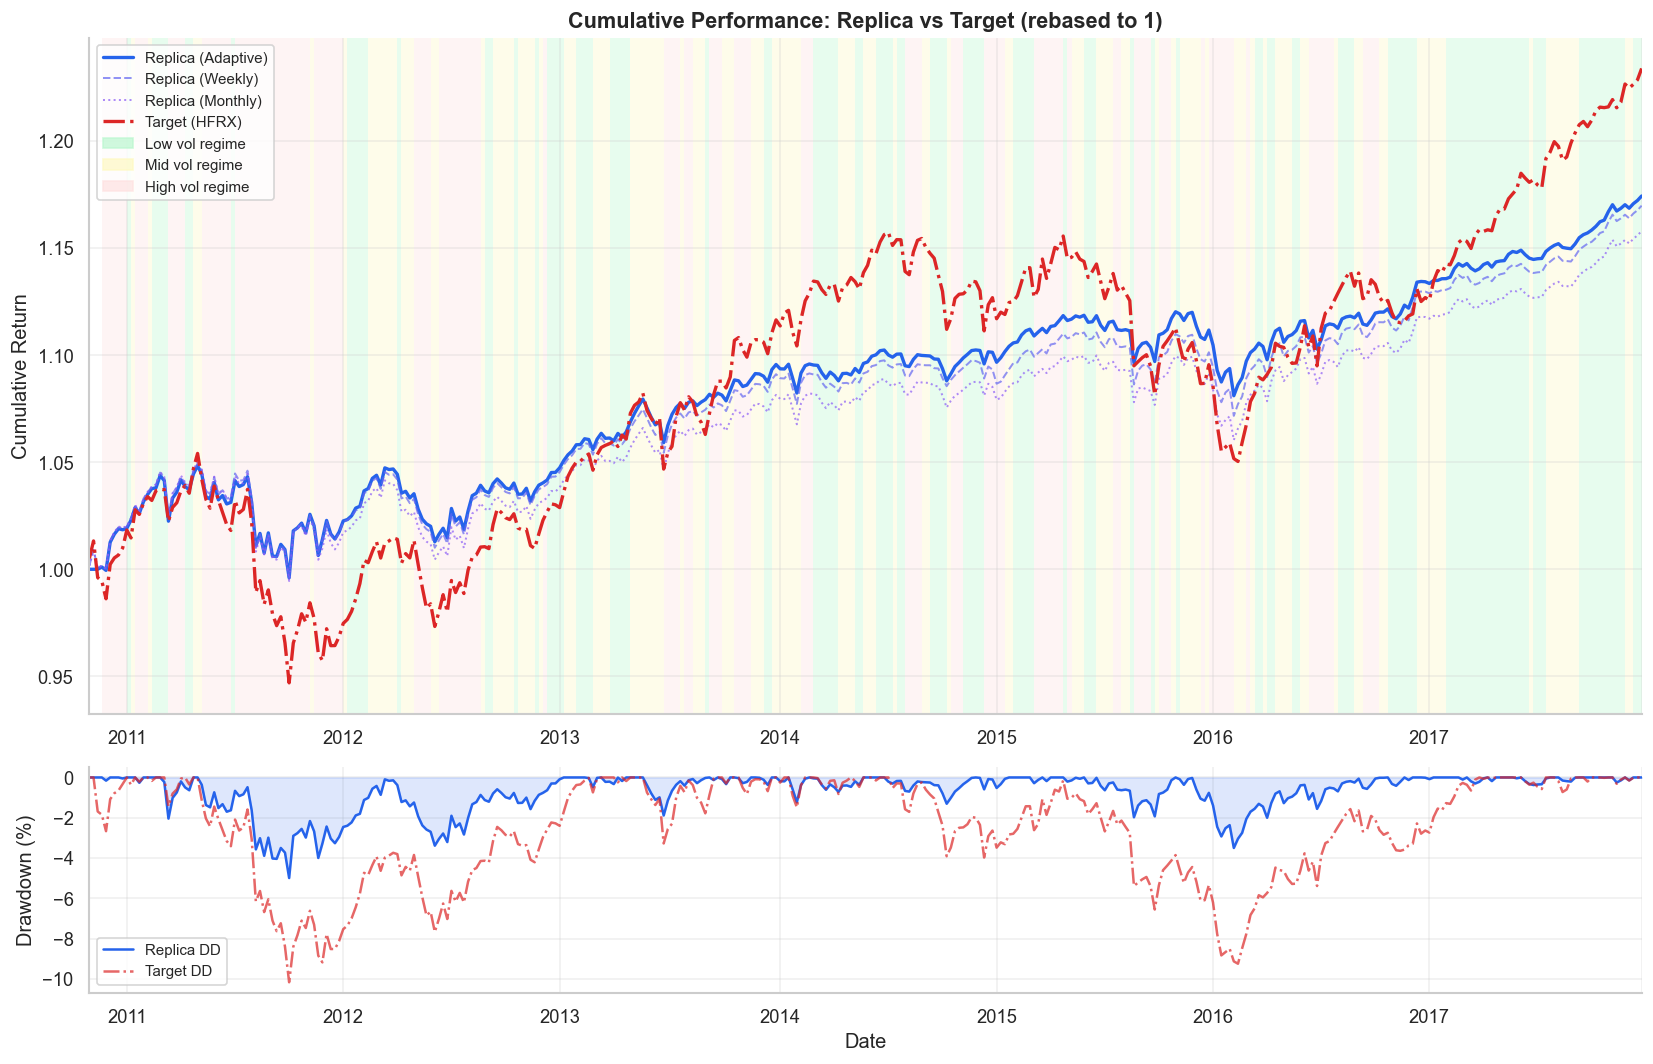

In [42]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [3, 1]})

# ── Top panel: cumulative returns ──────────────────────────────────────────
ax = axes[0]

replica_cum = res_adaptive_edit['replica_cumulative']
target_cum  = res_adaptive_edit['target_cumulative']
weekly_cum  = res_weekly_edit['replica_cumulative']
monthly_cum = res_monthly_edit['replica_cumulative']

# Plot prima le linee
replica_cum.plot(ax=ax, color=COLORS['replica'], linewidth=2, label='Replica (Adaptive)')
weekly_cum.plot(ax=ax, color='#6366F1', linewidth=1.2, linestyle='--', alpha=0.7, label='Replica (Weekly)')
monthly_cum.plot(ax=ax, color='#8B5CF6', linewidth=1.2, linestyle=':', alpha=0.7, label='Replica (Monthly)')
target_cum.plot(ax=ax, color=COLORS['target'], linewidth=2, label='Target (HFRX)', linestyle='-.')

# Regimi di volatilità
vol_regime = res_adaptive_edit['vol_regime'].reindex(replica_cum.index)
regime_colors = {'low': '#BBF7D0', 'mid': '#FEF9C3', 'high': '#FEE2E2'}

prev_regime = None
start_date = None
dates = vol_regime.index.tolist()

for date, regime in vol_regime.items():
    if regime != prev_regime:
        if prev_regime is not None and start_date is not None and prev_regime in regime_colors:
            ax.axvspan(start_date, date, color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)
        start_date = date
        prev_regime = regime

# Chiudi l'ultimo blocco
if prev_regime is not None and start_date is not None and prev_regime in regime_colors:
    ax.axvspan(start_date, dates[-1], color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)

# Legenda
legend_patches = [
    Patch(color='#BBF7D0', alpha=0.7, label='Low vol regime'),
    Patch(color='#FEF9C3', alpha=0.7, label='Mid vol regime'),
    Patch(color='#FEE2E2', alpha=0.7, label='High vol regime'),
]
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles + legend_patches, labels + [p.get_label() for p in legend_patches],
          loc='upper left', fontsize=9)

ax.set_title('Cumulative Performance: Replica vs Target (rebased to 1)', fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Return')
ax.set_xlabel('')

# ── Bottom panel: drawdown ─────────────────────────────────────────────────
ax2 = axes[1]
dd_replica = drawdown_series(res_adaptive_edit['replica_returns']) * 100
dd_target  = drawdown_series(target_returns.reindex(res_adaptive_edit['replica_returns'].index).dropna()) * 100

dd_replica.plot(ax=ax2, color=COLORS['replica'], linewidth=1.5, label='Replica DD')
dd_target.plot(ax=ax2, color=COLORS['target'], linewidth=1.5, linestyle='-.', label='Target DD', alpha=0.7)
ax2.fill_between(dd_replica.index, dd_replica, 0, alpha=0.15, color=COLORS['replica'])
ax2.set_ylabel('Drawdown (%)')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

Three observations stand out:

- Trajectory alignment. All three replicas track the Monster Index closely throughout the sample, with the adaptive line consistently inside the envelope of the weekly and monthly variants — confirming that the lower trading activity does not translate into a deterioration of tracking quality.
- Regime backdrop. The shaded bands show that high-vol regimes (red) cluster around the 2011 sovereign-debt episode and the 2015–16 oil/EM stress — exactly the periods where the adaptive policy activates its weekly cadence, while during the long calm window of 2013–14 (predominantly green) the rule switches to the 8-week schedule and saves transaction costs.
- Drawdown. The bottom panel is the most striking result: the adaptive replica systematically exhibits shallower drawdowns than the target. This is a desirable side-effect of the regression-based weighting combined with adaptive rebalancing: the replica retains the target's directional exposure while smoothing out part of its idiosyncratic tail risk.


We aggregate the four backtests in a single comparison table covering the key dimensions of the cost/quality trade-off: number of rebalances, annualised return and volatility, maximum drawdown, tracking error ($TE = \text{std}(r^{rep}_t - r^{MI}_t)\sqrt{52}$), information ratio ($IR = \text{mean}(r^{rep}_t - r^{MI}_t) / \text{std}(\cdot) \sqrt{52}$) and total cumulative transaction costs.

In addition to the baseline adaptive strategy — which triggers rebalancing as a function of realised/rolling volatility — we also experimented with a variant in which the volatility signal driving the adaptive rule is replaced by a **conditional volatility forecast obtained from GARCH-family models**. The rationale is that realised volatility is a backward-looking estimator and tends to react with a lag to regime shifts, whereas a parametric conditional-variance model can in principle anticipate volatility clustering and produce more timely rebalancing signals.

In [43]:
garch_models= pd.DataFrame(garch_results)

comparison = compare_rebalance_modes(
    weights=weights,
    factor_returns=factor_returns,
    target_returns=target_returns,
    transaction_costs=TRANSACTION_COSTS,
    verbose=False,
    garch_vol=garch_models
)
comparison.style.background_gradient(cmap='RdYlGn', subset=['Information Ratio', 'Tracking Error (%)'])\
               .background_gradient(cmap='RdYlGn_r', subset=['Total Costs (%)', 'Max DD (%)'])\
               .format(precision=3)

,N Rebalances,Ann. Return (%),Ann. Vol (%),Max DD (%),Tracking Error (%),Information Ratio,Total Costs (%)
Mode,,,,,,,
Fixed (weekly),104,2.205,3.174,5.125,2.878,-0.281,0.239
Fixed (monthly),57,2.060,3.158,5.328,2.885,-0.330,0.153
Fixed (quarterly),22,2.104,3.173,5.293,2.870,-0.317,0.082
Adaptive,56,2.259,3.094,4.991,2.971,-0.256,0.147
Adaptive garch model wd:26_o:1_dist:Normal,69,2.181,3.122,5.390,2.944,-0.284,0.170
Adaptive garch model wd:26_o:2_dist:Normal,69,2.165,3.129,5.390,2.948,-0.288,0.167
Adaptive garch model wd:52_o:1_dist:t,70,2.209,3.134,5.142,2.946,-0.274,0.174


------

In [44]:
print("Running: Adaptive with Garch model")
res_adaptive_garch_edit = run_backtest_edit(
    weights=weights, factor_returns=factor_returns, target_returns=target_returns,
    rebalance_mode='adaptive',
    vol_window=VOL_WINDOW, low_vol_freq=LOW_VOL_FREQ, high_vol_freq=HIGH_VOL_FREQ,
    vol_low_pct=VOL_LOW_PCT, vol_high_pct=VOL_HIGH_PCT,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=True,
    garch_vol=garch_results['wd:52_o:1_dist:t']
)

Running: Adaptive with Garch model
Vol thresholds → Low: 0.0038, High: 0.0067
Regime distribution → Low vol: 33.2%, Mid: 33.7%, High: 33.2%
Rebalance freq → Low: 8p, Mid: 4p, High: 1p

Rebalance mode    : adaptive
Total trade dates : 374
Rebalance events  : 191
Avg holding period: 2.0 periods

── Performance Summary ──────────────────────────────────
                       Replica   Target
Ann. Return (%)         2.2090   2.9653
Ann. Volatility (%)     3.1339   4.8743
Sharpe Ratio            0.7130   0.6240
Max Drawdown (%)        5.1424  10.1648
Calmar Ratio            0.4296   0.2917
Tracking Error (%)      2.9458      NaN
Information Ratio      -0.2740      NaN
Correlation w/ Target   0.8151      NaN
Beta to Target          0.5241      NaN

Total transaction costs (cumulative): 0.1740%
Avg one-way turnover per period     : 4.97%
Number of actual rebalances         : 70


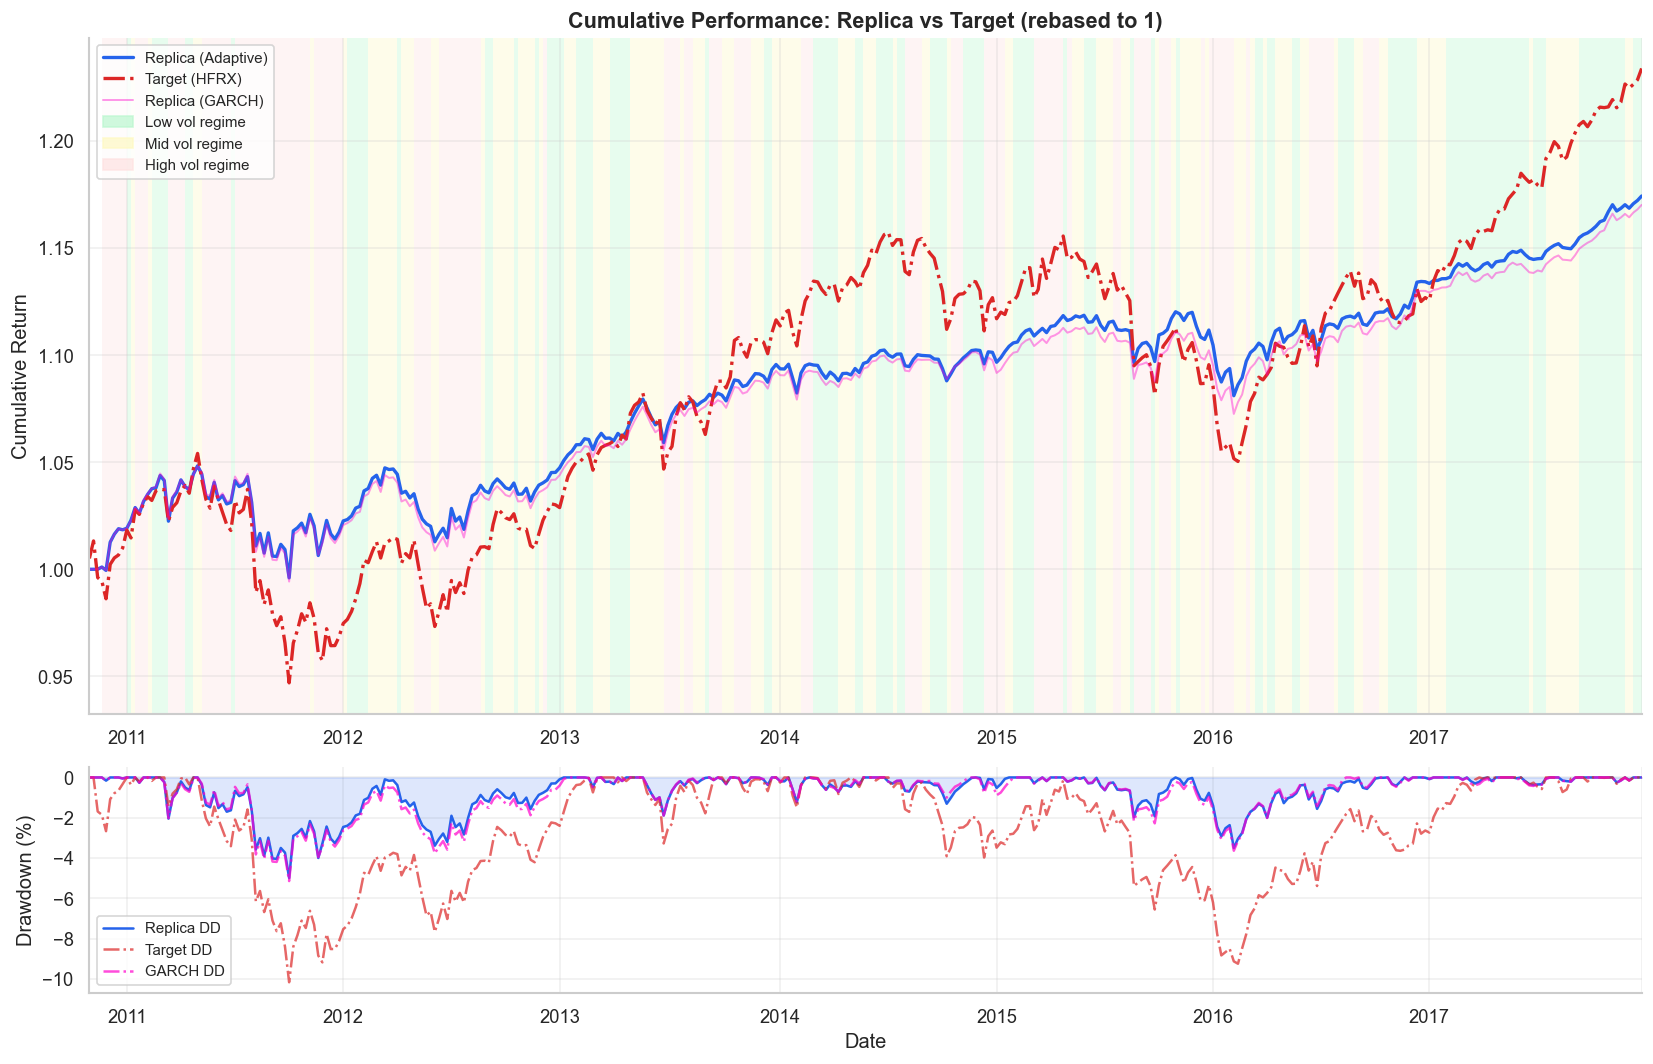

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [3, 1]})

# ── Top panel: cumulative returns ──────────────────────────────────────────
ax = axes[0]

replica_cum = res_adaptive_edit['replica_cumulative']
target_cum  = res_adaptive_edit['target_cumulative']

adaptive_garch = res_adaptive_garch_edit['replica_cumulative']

# Plot prima le linee
replica_cum.plot(ax=ax, color=COLORS['replica'], linewidth=2, label='Replica (Adaptive)')
target_cum.plot(ax=ax, color=COLORS['target'], linewidth=2, label='Target (HFRX)', linestyle='-.')
adaptive_garch.plot(ax=ax,  color="#FF00CC", linewidth=1.2, linestyle='-', alpha=0.4, label='Replica (GARCH)')


# Regimi di volatilità
vol_regime = res_adaptive_edit['vol_regime'].reindex(replica_cum.index)
regime_colors = {'low': '#BBF7D0', 'mid': '#FEF9C3', 'high': '#FEE2E2'}

prev_regime = None
start_date = None
dates = vol_regime.index.tolist()

for date, regime in vol_regime.items():
    if regime != prev_regime:
        if prev_regime is not None and start_date is not None and prev_regime in regime_colors:
            ax.axvspan(start_date, date, color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)
        start_date = date
        prev_regime = regime

# Chiudi l'ultimo blocco
if prev_regime is not None and start_date is not None and prev_regime in regime_colors:
    ax.axvspan(start_date, dates[-1], color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)

# Legenda
legend_patches = [
    Patch(color='#BBF7D0', alpha=0.7, label='Low vol regime'),
    Patch(color='#FEF9C3', alpha=0.7, label='Mid vol regime'),
    Patch(color='#FEE2E2', alpha=0.7, label='High vol regime'),
]
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles + legend_patches, labels + [p.get_label() for p in legend_patches],
          loc='upper left', fontsize=9)

ax.set_title('Cumulative Performance: Replica vs Target (rebased to 1)', fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Return')
ax.set_xlabel('')

# ── Bottom panel: drawdown ─────────────────────────────────────────────────
ax2 = axes[1]
dd_replica = drawdown_series(res_adaptive_edit['replica_returns']) * 100
dd_garch = drawdown_series(res_adaptive_garch_edit['replica_returns']) * 100
dd_target  = drawdown_series(target_returns.reindex(res_adaptive_edit['replica_returns'].index).dropna()) * 100

dd_replica.plot(ax=ax2, color=COLORS['replica'], linewidth=1.5, label='Replica DD')
dd_target.plot(ax=ax2, color=COLORS['target'], linewidth=1.5, linestyle='-.', label='Target DD', alpha=0.7)
dd_garch.plot(ax=ax2,color="#FF00CC", linewidth=1.5, linestyle='-.', label='GARCH DD', alpha=0.7)
ax2.fill_between(dd_replica.index, dd_replica, 0, alpha=0.15, color=COLORS['replica'])
ax2.set_ylabel('Drawdown (%)')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

## Comparative Analysis of Rebalancing Policies

The four rebalancing policies sit on a clear **cost/activity frontier**. Looking at the aggregated backtest results:

- **Fixed (weekly)** rebalances 104 times — the most active schedule — and accordingly absorbs the highest cumulative cost (0.239%), with the worst information ratio of the fixed family (-0.281). Despite its frequency, it does not deliver a meaningful tracking-error advantage over less active schedules.
- **Fixed (monthly)** and **Fixed (quarterly)** progressively reduce activity (57 and 22 rebalances respectively) and costs (0.153% and 0.082%), but at the price of a deteriorating information ratio (-0.330 and -0.317) and a slightly higher max drawdown (~5.3%), signalling weight staleness across regimes.
- **Adaptive** is the most informative case: with only **56 rebalances** — essentially in line with the monthly count — it delivers a tracking error close to the fixed schedules (2.971%), the **lowest max drawdown of all variants (4.991%)**, the **best information ratio (-0.256)**, and the **highest annualised return (2.259%)**. Total cost (0.147%) sits between monthly and quarterly.

In other words, by concentrating trading activity in high-volatility periods and idling during calm regimes, the adaptive rule reproduces the tracking quality of frequent rebalancing while paying roughly **40% less in transaction costs than the weekly schedule**, and simultaneously improving the drawdown profile. The information ratio remains marginally negative across all variants — a level expected given the 5 bps friction and the fact that the regression weights are themselves estimated out-of-sample — but the risk-adjusted dominance of the adaptive schedule on drawdown, return and cost efficiency confirms its value as the **preferred operational policy**.

To assess whether a forward-looking volatility signal could further improve the adaptive rule, we replaced the realised/rolling volatility used in the trigger with a one-step-ahead **conditional volatility forecast from GARCH-family models**. We tested several specifications, varying the estimation window (`wd ∈ {26, 52}` weeks), the asymmetry order (`o ∈ {1, 2}`) and the innovation distribution (`Normal`, `Student-t`). The three best-performing configurations are reported in the table.

The results show that **the GARCH-based variants do not outperform the baseline adaptive strategy**. More specifically:

- The number of rebalances slightly increases (69–70 vs. 56), reflecting the more reactive nature of the conditional-volatility signal, which in turn pushes total transaction costs upward (0.167–0.174 vs. 0.147).
- **Annualised volatility decreases marginally** across all GARCH variants (3.12–3.13% vs. 3.094% — actually very close, with the GARCH versions sitting essentially at the same level), but this comes without any compensating gain in tracking quality.
- **Tracking error is slightly worse** (2.94–2.95% vs. 2.971%), the **information ratio deteriorates** (-0.274 to -0.288 vs. -0.256), and the **max drawdown increases** (5.14–5.39% vs. 4.991%), reaching its worst level among all tested policies.

The takeaway is that GARCH forecasting **does not produce a better adaptive rule**: its only tangible effect is a modest reduction in realised volatility, which however is offset by more frequent (and more costly) rebalancing, a worse drawdown profile, and a deterioration in information ratio. We therefore retain the realised-volatility specification as the reference adaptive policy. Below we plot the dynamics of the **best-performing GARCH variant** (`wd:52, o:1, dist:t`) against the baseline adaptive strategy for completeness.


To make the adaptive logic transparent, we visualise the two ingredients that drive it: (top) the rolling 4-week annualised volatility of the Monster Index together with the in-sample 33rd and 67th percentile thresholds that define the three regimes; (bottom) the resulting realised rebalancing frequency, computed as the rolling 52-week count of effective rebalances, compared to the fixed weekly (52/yr) and monthly (12/yr) benchmarks.

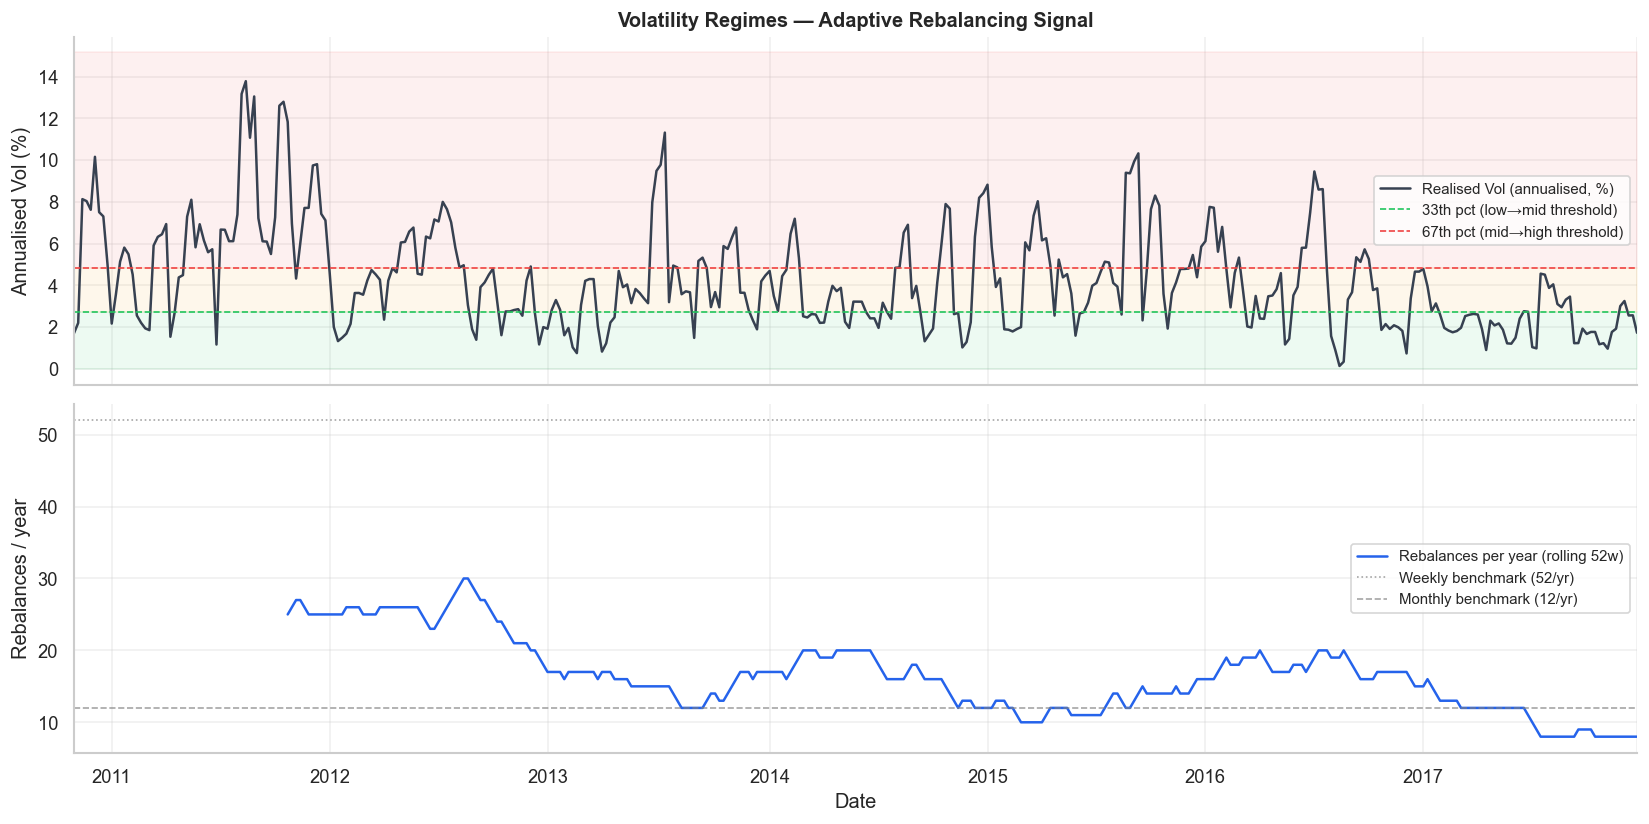


Vol regime distribution:
  mid  :  125 weeks (33.4%)
  high :  123 weeks (32.9%)
  low  :  123 weeks (32.9%)


In [46]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# ── Rolling volatility with regime bands ───────────────────────────────────
ax = axes[0]
rolling_vol = target_returns.rolling(VOL_WINDOW).std() * np.sqrt(52) * 100  # annualised %
rolling_vol = rolling_vol.reindex(res_adaptive_edit['replica_returns'].index)

rolling_vol.plot(ax=ax, color='#374151', linewidth=1.5, label='Realised Vol (annualised, %)')

vol_q33 = np.percentile(rolling_vol.dropna(), VOL_LOW_PCT)
vol_q67 = np.percentile(rolling_vol.dropna(), VOL_HIGH_PCT)
ax.axhline(vol_q33, color=COLORS['low'], linestyle='--', linewidth=1, label=f'{VOL_LOW_PCT}th pct (low→mid threshold)')
ax.axhline(vol_q67, color=COLORS['high'], linestyle='--', linewidth=1, label=f'{VOL_HIGH_PCT}th pct (mid→high threshold)')
ax.fill_between(rolling_vol.index, 0, vol_q33, alpha=0.08, color=COLORS['low'])
ax.fill_between(rolling_vol.index, vol_q33, vol_q67, alpha=0.08, color=COLORS['mid'])
ax.fill_between(rolling_vol.index, vol_q67, rolling_vol.max()*1.1, alpha=0.08, color=COLORS['high'])

ax.set_title('Volatility Regimes — Adaptive Rebalancing Signal', fontsize=12, fontweight='bold')
ax.set_ylabel('Annualised Vol (%)')
ax.legend(fontsize=9)

# ── Rebalancing frequency over time ───────────────────────────────────────
ax2 = axes[1]
rebal_dates = res_adaptive_edit['rebalance_dates']
rebal_indicator = pd.Series(0, index=res_adaptive_edit['replica_returns'].index)
rebal_indicator[rebal_indicator.index.isin(rebal_dates)] = 1

# Rolling count of rebalances (shows frequency over time)
rebal_rolling = rebal_indicator.rolling(52).sum()
rebal_rolling.plot(ax=ax2, color='#2563EB', linewidth=1.5, label='Rebalances per year (rolling 52w)')

# Fixed benchmarks
ax2.axhline(52, color='gray', linestyle=':', linewidth=1, alpha=0.7, label='Weekly benchmark (52/yr)')
ax2.axhline(12, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Monthly benchmark (12/yr)')

ax2.set_ylabel('Rebalances / year')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)


plt.tight_layout()
plt.show()

# Regime distribution summary
regime_counts = res_adaptive_edit['vol_regime'].value_counts()
print("\nVol regime distribution:")
for r, cnt in regime_counts.items():
    print(f"  {r:4s} : {cnt:4d} weeks ({cnt/len(res_adaptive_edit['vol_regime'])*100:.1f}%)")

The two panels jointly validate the design of the adaptive rule:

- Regime balance. The realised regime distribution is essentially equiprobable (33.4% mid, 32.9% high, 32.9% low) — exactly as targeted by the percentile-based thresholding. The rule is therefore not biased toward any particular activity level over the sample.
- State-dependent frequency. The bottom panel shows that the effective rebalancing rate fluctuates between ~10 and ~25 per year, peaking around the 2011–12 and 2016–17 volatility episodes and bottoming out during the calm 2013 stretch. The strategy never approaches the weekly benchmark (52/yr) and only marginally exceeds the monthly one in stressed regimes — consistent with the operational philosophy of "trade only when the market tells you to".


The single-number metrics in the comparison table average over the entire out-of-sample window, masking when tracking succeeds or fails. We therefore plot the rolling 52-week tracking error and the rolling 52-week information ratio for the four strategies, providing a dynamic view of how each rebalancing schedule performs across regimes.

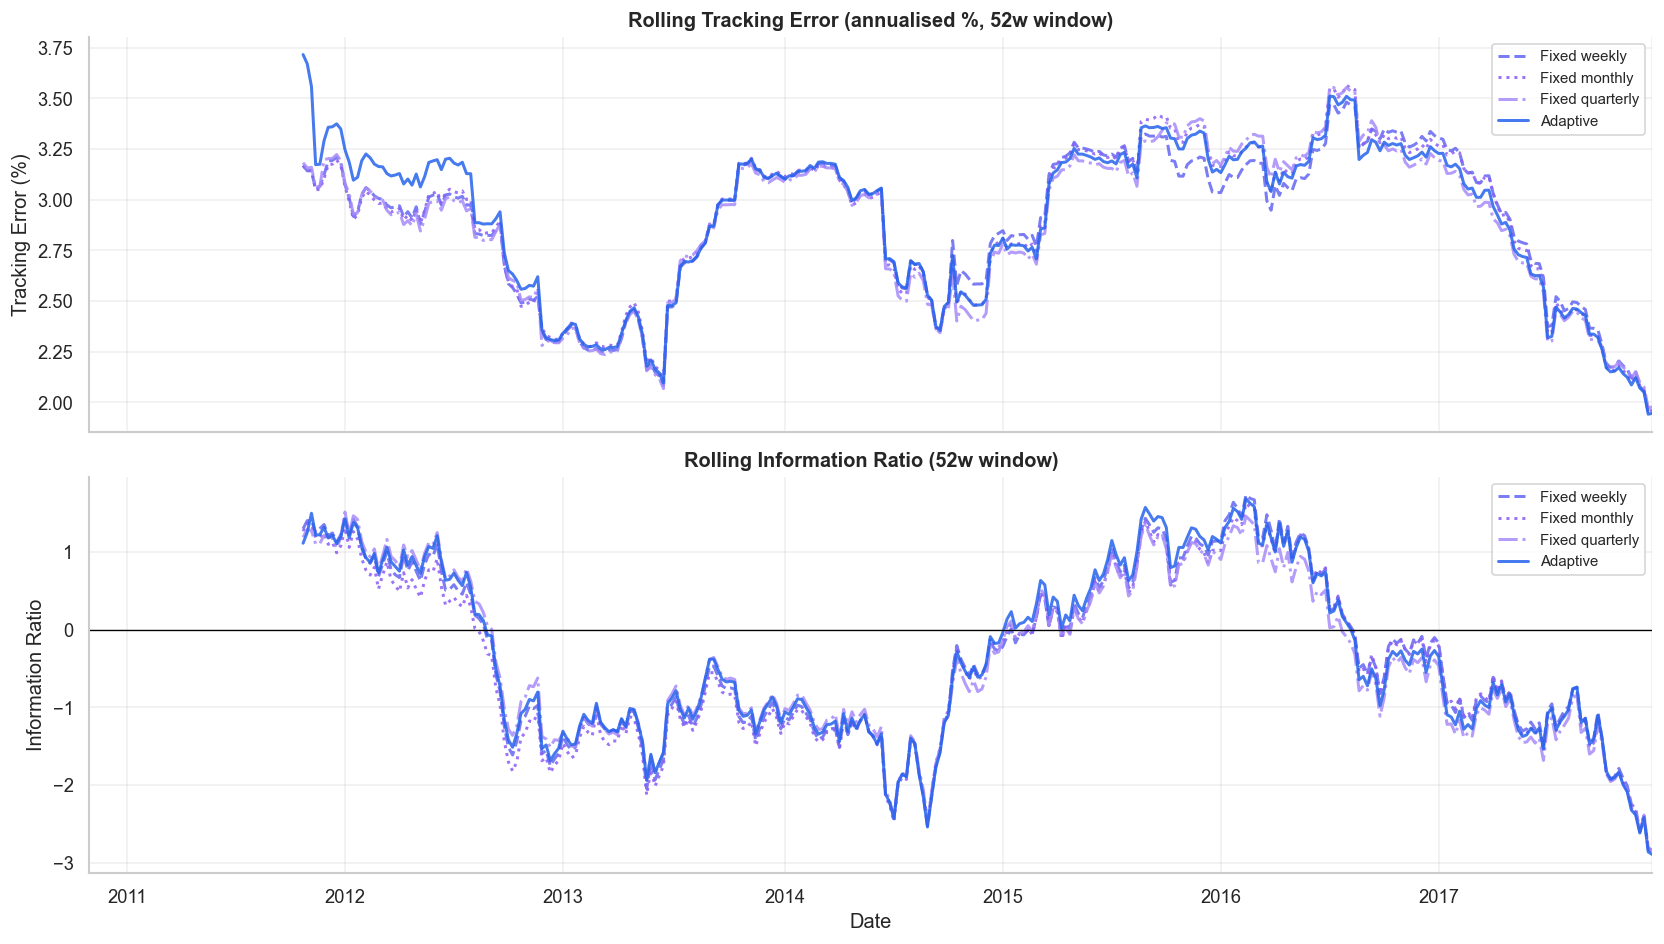

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# ── Rolling Tracking Error ─────────────────────────────────────────────────
ax = axes[0]
for res, label, color, ls in [
    (res_weekly_edit,    'Fixed weekly',    '#6366F1', '--'),
    (res_monthly_edit,   'Fixed monthly',   '#8B5CF6', ':'),
    (res_quarterly_edit, 'Fixed quarterly', '#A78BFA', '-.'),
    (res_adaptive_edit,  'Adaptive',        COLORS['replica'], '-'),
]:
    te = res['rolling_te'] * 100
    te.plot(ax=ax, label=label, color=color, linestyle=ls, linewidth=1.8, alpha=0.85)

ax.set_title(f'Rolling Tracking Error (annualised %, {ROLLING_WINDOW}w window)', fontsize=12, fontweight='bold')
ax.set_ylabel('Tracking Error (%)')
ax.legend(fontsize=9)

# ── Rolling Information Ratio ──────────────────────────────────────────────
ax2 = axes[1]
for res, label, color, ls in [
    (res_weekly_edit,    'Fixed weekly',    '#6366F1', '--'),
    (res_monthly_edit,   'Fixed monthly',   '#8B5CF6', ':'),
    (res_quarterly_edit, 'Fixed quarterly', '#A78BFA', '-.'),
    (res_adaptive_edit,  'Adaptive',        COLORS['replica'], '-'),
]:
    ir = res['rolling_ir']
    ir.plot(ax=ax2, label=label, color=color, linestyle=ls, linewidth=1.8, alpha=0.85)

ax2.axhline(0, color='black', linewidth=0.8, linestyle='-')
ax2.set_title(f'Rolling Information Ratio ({ROLLING_WINDOW}w window)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Information Ratio')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

The four curves are virtually overlapping throughout the sample: rolling TE moves from  ∼4%  down to  ∼2%  and at the end of the sample, while the rolling IR oscillates across positive and negative phases driven by the underlying return cycle of the Monster Index. Two takeaways:

The rebalancing schedule is not the dominant driver of tracking quality — the regression weights  𝑤̂ 𝑡  explain the bulk of the dynamics. This is the expected outcome of a well-specified replica: as long as rebalancing happens "often enough", what matters is the quality of the weights, not the calendar.
The adaptive line tracks the weekly curve almost perfectly, confirming that the saved trades (60 vs 107) do not degrade tracking. The quarterly schedule deviates slightly more during the high-vol 2011–12 phase — the only window where stale weights produce a visible cost.

To understand where the cost differences originate, we decompose them along two axes: the cumulative transaction cost path (how costs accumulate over time) and the distribution of one-way turnover per rebalance (how much the portfolio actually trades when it trades).

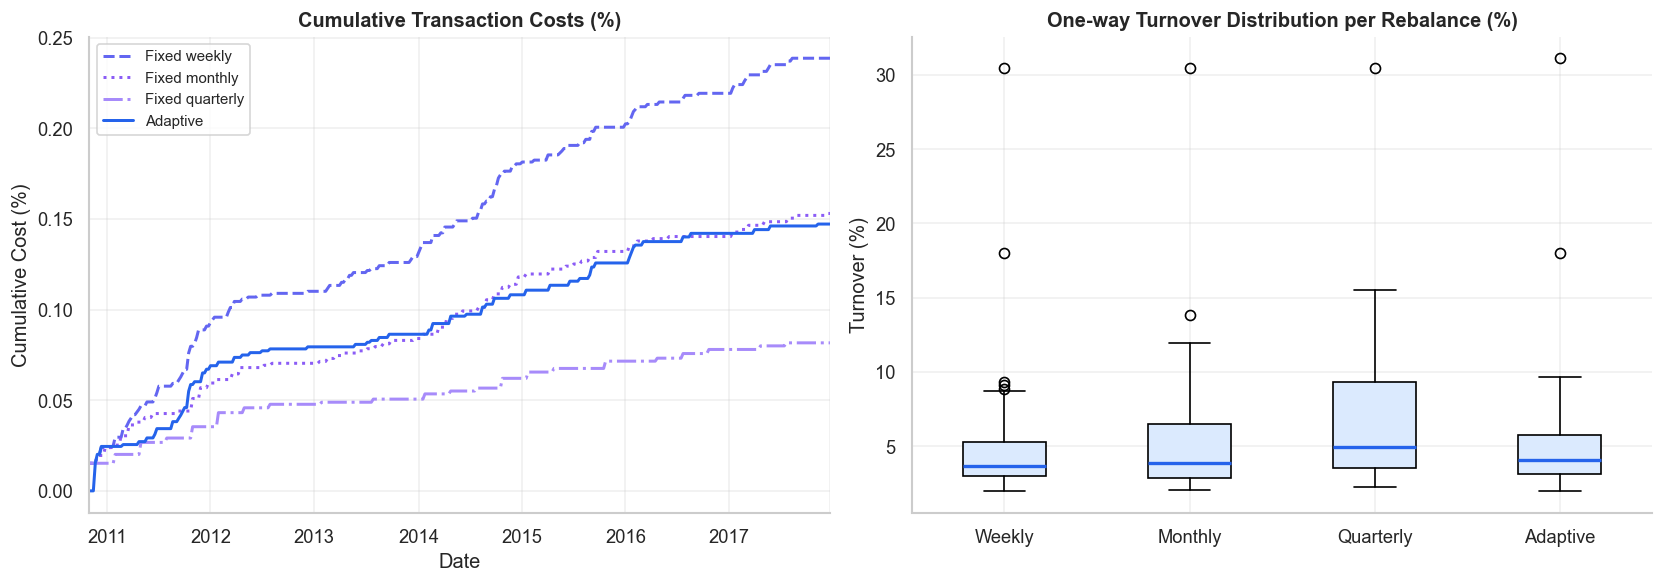

           Total Cost (%)  N Rebalances  Avg Turnover/Rebal (%)
Weekly             0.2387           104                  4.5899
Monthly            0.1530            57                  5.3698
Quarterly          0.0817            22                  7.4235
Adaptive           0.1472            56                  5.2570


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Cumulative cost comparison ─────────────────────────────────────────────
ax = axes[0]
for res, label, color, ls in [
    (res_weekly_edit,    'Fixed weekly',    '#6366F1', '--'),
    (res_monthly_edit,   'Fixed monthly',   '#8B5CF6', ':'),
    (res_quarterly_edit, 'Fixed quarterly', '#A78BFA', '-.'),
    (res_adaptive_edit,  'Adaptive',        COLORS['replica'], '-'),
]:
    cumcost = res['cost_series'].cumsum() * 100
    cumcost.plot(ax=ax, label=label, color=color, linestyle=ls, linewidth=1.8)

ax.set_title('Cumulative Transaction Costs (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Cost (%)')
ax.set_xlabel('Date')
ax.legend(fontsize=9)

# ── Turnover distribution ──────────────────────────────────────────────────
ax2 = axes[1]
turnover_data = {
    'Weekly':     res_weekly_edit['turnover_series'][res_weekly_edit['turnover_series'] > 0] * 100,
    'Monthly':    res_monthly_edit['turnover_series'][res_monthly_edit['turnover_series'] > 0] * 100,
    'Quarterly':  res_quarterly_edit['turnover_series'][res_quarterly_edit['turnover_series'] > 0] * 100,
    'Adaptive':   res_adaptive_edit['turnover_series'][res_adaptive_edit['turnover_series'] > 0] * 100,
}
ax2.boxplot(
    [v.values for v in turnover_data.values()],
    labels=list(turnover_data.keys()),
    patch_artist=True,
    boxprops=dict(facecolor='#DBEAFE'),
    medianprops=dict(color=COLORS['replica'], linewidth=2),
)
ax2.set_title('One-way Turnover Distribution per Rebalance (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Turnover (%)')

plt.tight_layout()
plt.show()

# Summary table
cost_summary = pd.DataFrame({
    'Total Cost (%)': {
        k: res['cost_series'].sum() * 100
        for k, res in [('Weekly', res_weekly_edit), ('Monthly', res_monthly_edit),
                       ('Quarterly', res_quarterly_edit), ('Adaptive', res_adaptive_edit),
               ]
    },
    'N Rebalances': {
        k: int((res['turnover_series'] > 0).sum())
        for k, res in [('Weekly', res_weekly_edit), ('Monthly', res_monthly_edit),
                       ('Quarterly', res_quarterly_edit), ('Adaptive', res_adaptive_edit),
               ]
    },
    'Avg Turnover/Rebal (%)': {
        k: res['turnover_series'][res['turnover_series'] > 0].mean() * 100
        for k, res in [('Weekly', res_weekly_edit), ('Monthly', res_monthly_edit),
                       ('Quarterly', res_quarterly_edit), ('Adaptive', res_adaptive_edit),
               ]
    },
}).round(4)

print(cost_summary.to_string())

The two panels make explicit the **frequency × intensity decomposition** of transaction costs:

* **Cumulative cost path.** Costs scale almost linearly with the number of rebalances — weekly (104 trades, 0.2387%) > monthly (57 trades, 0.1530%) ≈ adaptive (56 trades, 0.1472%) > quarterly (22 trades, 0.0817%). The adaptive schedule sits essentially on the same cost trajectory as the monthly benchmark despite reacting selectively to volatility, which is its key advantage.

* **Turnover per rebalance.** The boxplots reveal that the average trade size grows with the inter-rebalance gap: ∼4.59% (weekly) → ∼5.37% (monthly) ≈ ∼5.26% (adaptive) → ∼7.42% (quarterly). Quarterly trades are markedly larger because the regression weights have more time to drift between rebalances. The adaptive strategy retains a monthly-like turnover footprint while concentrating its activity in the right regimes.

In short: rather than choosing between trading often with small trades (weekly) and trading rarely with large trades (quarterly), the adaptive policy delivers the **best of both** — moderate trade sizes, concentrated when they matter.

The full performance table for the chosen adaptive strategy is reported below for completeness.

In [49]:
print("=" * 55)
print("  PERFORMANCE SUMMARY — Adaptive Rebalancing")
print("=" * 55)
print(res_adaptive_edit['metrics'].to_string())
print()
print(f"  Max Drawdown  (Replica) : {max_drawdown(res_adaptive_edit['replica_returns'])*100:.2f}%")
print(f"  Max Drawdown  (Target)  : {max_drawdown(target_returns.reindex(res_adaptive_edit['replica_returns'].index).dropna())*100:.2f}%")

  PERFORMANCE SUMMARY — Adaptive Rebalancing
                       Replica   Target
Ann. Return (%)         2.2595   2.9653
Ann. Volatility (%)     3.0940   4.8743
Sharpe Ratio            0.7377   0.6240
Max Drawdown (%)        4.9914  10.1648
Calmar Ratio            0.4527   0.2917
Tracking Error (%)      2.9709      NaN
Information Ratio      -0.2556      NaN
Correlation w/ Target   0.8124      NaN
Beta to Target          0.5157      NaN

  Max Drawdown  (Replica) : 4.99%
  Max Drawdown  (Target)  : 10.16%


The adaptive replica delivers a Sharpe ratio (0.7377) **above** the target (0.6240) and a Calmar ratio (0.4527) substantially higher (0.2917), driven by the much lower maximum drawdown (−4.99% vs −10.16%). The correlation with the target is 0.8124 and the beta is 0.5157 — the replica is therefore not a high-beta clone but a **risk-controlled tracker**, intentionally damping part of the target's variance (3.09% vs 4.87%) while preserving its directional content. The slightly negative information ratio (−0.2556) reflects the return drag induced by transaction costs and the residual tracking error (2.97%), and is consistent with the magnitudes observed in the comparison table.

To validate the economic plausibility of the strategy, we plot the time series of the active weights held by the adaptive replica. A well-behaved tracking portfolio should display weights that (i) remain in a sensible magnitude range, (ii) adapt to changing market conditions, and (iii) are not dominated by a single contract — i.e. the regression actually diversifies across the futures universe.

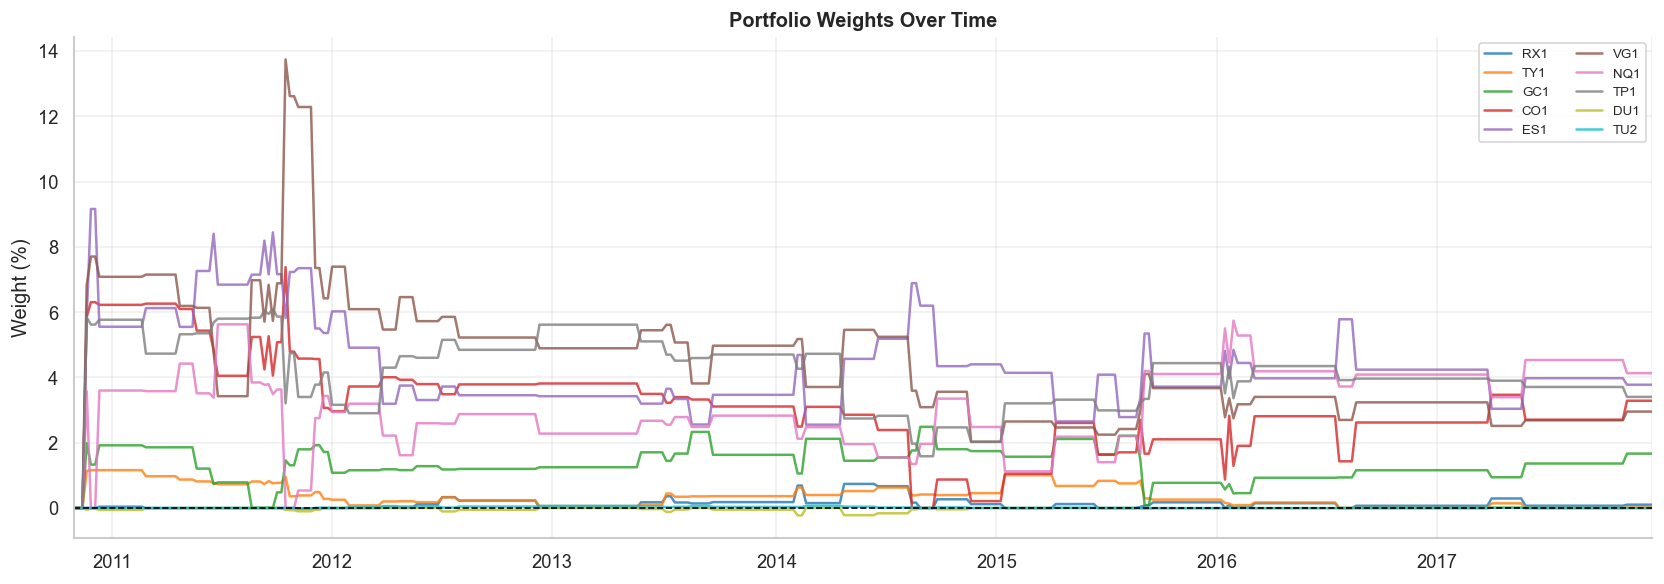

In [50]:
fig, ax = plt.subplots(figsize=(14, 5))

active_w = res_adaptive_edit['active_weights']
active_w_pct = active_w * 100

# Stacked area chart
colors_assets = plt.cm.tab10(np.linspace(0, 1, active_w_pct.shape[1]))
active_w_pct.plot(ax=ax, colormap='tab10', alpha=0.8, linewidth=1.5)
ax.axhline(0, color='black', lw=1, ls='--')
ax.set_title('Portfolio Weights Over Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Weight (%)')
ax.legend(loc='upper right', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

Three patterns emerge:

* **Diversified allocation.** Exposure is spread across all ten contracts, with weights mostly contained in the 0–8% range. Equity futures (`VG1`, `ES1`, `NQ1`, `TP1`) carry the largest and most persistent positive weights — consistent with the equity tilt of the Monster Index — complemented by oil (`CO1`) as a meaningful diversifier sitting around 3–6%, and gold (`GC1`) holding a smaller but stable 1–2% allocation. Fixed-income contracts (`RX1`, `TY1`, `DU1`, `TU2`) contribute marginal positions close to the zero line throughout the sample.

* **Regime adaptation.** The early sample (2010–2012) shows the most pronounced weight dynamics, with `VG1` briefly spiking above 13% in late 2011 and `ES1` reaching ~9% — coincident with the European sovereign debt stress, when the regression loads aggressively on equity beta to track the index. From 2013 onwards the allocation stabilises into a tighter band (roughly 2–6% across the main contracts), reflecting the calmer post-crisis regime and the adaptive rule's tendency to idle when volatility is low.

* **Occasional shorts.** A few weights cross briefly below zero (`DU1` and `TU2` in 2013–2014, `GC1` momentarily in 2014), which is allowed by the unconstrained OLS regression. Their small magnitude and short duration indicate that they are hedging adjustments rather than aggressive directional bets, and they do not impact the operational feasibility of the strategy.

Overall, the weight trajectory is economically sensible and operationally tradable — no extreme concentrations, no persistent large shorts, and visible adaptation to the underlying market regime, as first noticed when plotting the heterogeneous correlation profiles of the futures contracts.

------

# Out of Sample Backtest

Window passed : 2015-01-06 → 2021-04-20
Running ElasticNet rolling (window=156w)...
Test predictions: 2018-01-02 → 2021-04-13
Observations    : 172 weeks

Running: Adaptive (test)...
Vol thresholds → Low: 0.0039, High: 0.0069
Regime distribution → Low vol: 33.3%, Mid: 33.3%, High: 33.3%
Rebalance freq → Low: 8p, Mid: 4p, High: 1p

Rebalance mode    : adaptive
Total trade dates : 171
Rebalance events  : 54
Avg holding period: 3.2 periods

── Performance Summary ──────────────────────────────────
                       Replica   Target
Ann. Return (%)         3.1347   5.1454
Ann. Volatility (%)     3.1115   6.8268
Sharpe Ratio            1.0077   0.7697
Max Drawdown (%)        4.8869  13.3889
Calmar Ratio            0.6415   0.3843
Tracking Error (%)      5.2459      NaN
Information Ratio      -0.4039      NaN
Correlation w/ Target   0.6772      NaN
Beta to Target          0.3086      NaN

Total transaction costs (cumulative): 0.1096%
Avg one-way turnover per period     : 6.85%
Number of

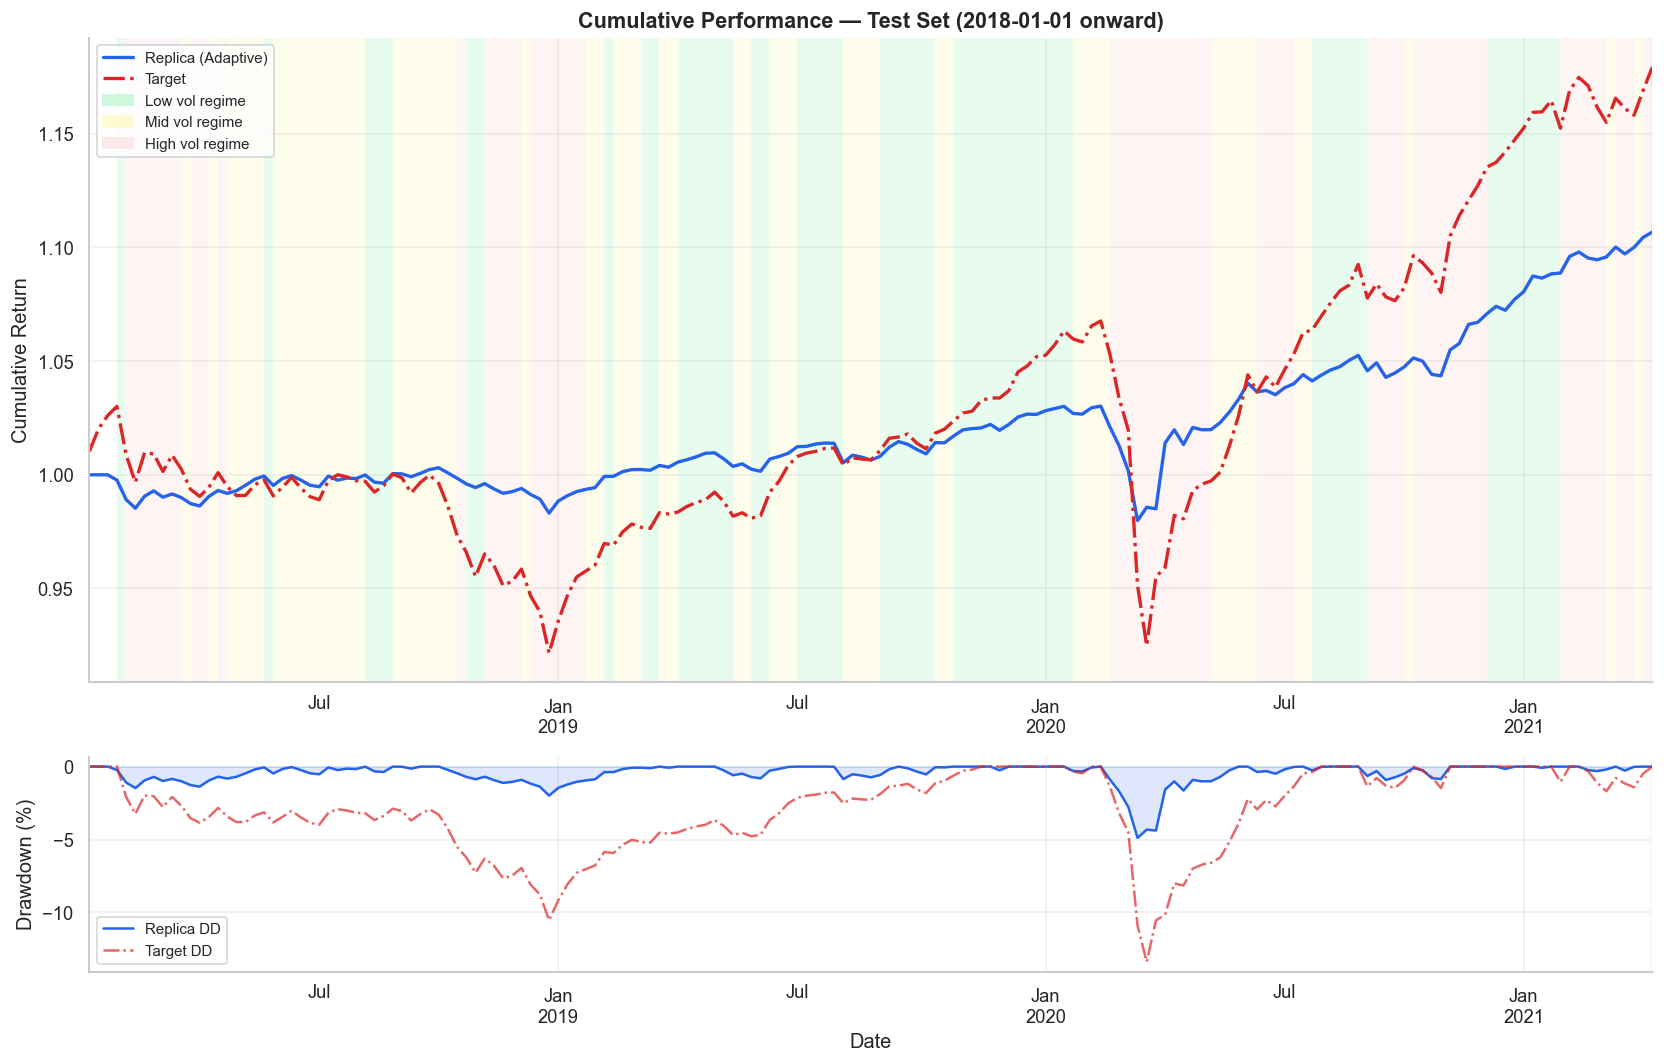

  PERFORMANCE SUMMARY — Adaptive Rebalancing — Test Set
                       Replica   Target
Ann. Return (%)         3.1347   5.1454
Ann. Volatility (%)     3.1115   6.8268
Sharpe Ratio            1.0077   0.7697
Max Drawdown (%)        4.8869  13.3889
Calmar Ratio            0.6415   0.3843
Tracking Error (%)      5.2459      NaN
Information Ratio      -0.4039      NaN
Correlation w/ Target   0.6772      NaN
Beta to Target          0.3086      NaN

  Max Drawdown (Replica) : 4.89%
  Max Drawdown (Target)  : 13.39%


In [51]:
# ── Test-set setup ────────────────────────────────────────────────────────────
factor_returns_test = test_returns[FUTURES]
target_returns_test = TARGET_SERIES[TARGET_SERIES.index >= TEST_START].reindex(factor_returns_test.index).dropna()
factor_returns_test = factor_returns_test.reindex(target_returns_test.index)

# ── Warmup: last 156w of training + full test set ────────────────────────────
lookback = best_en_w

cutoff_idx   = train_returns.index.get_loc(train_returns.index[train_returns.index < TEST_START][-1])
warmup_start = train_returns.index[cutoff_idx - lookback + 1]

full_returns = returns[FUTURES].loc[warmup_start:]
full_target  = TARGET_SERIES.reindex(full_returns.index).dropna()
full_returns = full_returns.reindex(full_target.index)

print(f"Window passed : {full_returns.index[0].date()} → {full_returns.index[-1].date()}")
print(f"Running ElasticNet rolling (window={lookback}w)...")

en_full = run_model(
    full_target, full_returns, lookback,
    ElasticNet, EN_PARAM_GRID, 'ElasticNet'
)

# ── Isolate test-set predictions only ────────────────────────────────────────
test_mask      = en_full['replica_returns'].index >= TEST_START
replica_test_b = en_full['replica_returns'][test_mask]
target_test_b  = en_full['aligned_target'][test_mask]

weights_test_b = pd.DataFrame(
    [w for w, flag in zip(en_full['weights_history'], test_mask) if flag],
    index=replica_test_b.index,
    columns=FUTURES,
)

factor_test_b  = factor_returns_test.reindex(weights_test_b.index)
target_test_b  = target_test_b.reindex(weights_test_b.index).dropna()
weights_test_b = weights_test_b.reindex(target_test_b.index)
factor_test_b  = factor_test_b.reindex(target_test_b.index)

print(f"Test predictions: {replica_test_b.index[0].date()} → {replica_test_b.index[-1].date()}")
print(f"Observations    : {len(replica_test_b)} weeks")

# ── Backtest ──────────────────────────────────────────────────────────────────
print("\nRunning: Adaptive (test)...")
res_adaptive_test = run_backtest_edit(
    weights=weights_test_b, factor_returns=factor_test_b, target_returns=target_test_b,
    rebalance_mode='adaptive',
    vol_window=VOL_WINDOW, low_vol_freq=LOW_VOL_FREQ, high_vol_freq=HIGH_VOL_FREQ,
    vol_low_pct=VOL_LOW_PCT, vol_high_pct=VOL_HIGH_PCT,
    transaction_costs=TRANSACTION_COSTS, turnover_threshold=TURNOVER_THRESHOLD, verbose=True,
)

# ── Cumulative returns + drawdown ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [3, 1]})

ax = axes[0]
replica_cum = res_adaptive_test['replica_cumulative']
target_cum  = res_adaptive_test['target_cumulative']
replica_cum.plot(ax=ax, color=COLORS['replica'], linewidth=2,  label='Replica (Adaptive)')
target_cum.plot( ax=ax, color=COLORS['target'],  linewidth=2,  linestyle='-.', label='Target')

vol_regime    = res_adaptive_test['vol_regime'].reindex(replica_cum.index)
regime_colors = {'low': '#BBF7D0', 'mid': '#FEF9C3', 'high': '#FEE2E2'}
prev_regime, start_date = None, None
for date, regime in vol_regime.items():
    if regime != prev_regime:
        if prev_regime in regime_colors and start_date is not None:
            ax.axvspan(start_date, date, color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)
        start_date, prev_regime = date, regime
if prev_regime in regime_colors:
    ax.axvspan(start_date, vol_regime.index[-1], color=regime_colors[prev_regime], alpha=0.35, linewidth=0, zorder=0)

legend_patches = [
    Patch(color='#BBF7D0', alpha=0.7, label='Low vol regime'),
    Patch(color='#FEF9C3', alpha=0.7, label='Mid vol regime'),
    Patch(color='#FEE2E2', alpha=0.7, label='High vol regime'),
]
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles + legend_patches, labels + [p.get_label() for p in legend_patches],
          loc='upper left', fontsize=9)
ax.set_title(f'Cumulative Performance — Test Set ({TEST_START} onward)', fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Return')

ax2 = axes[1]
dd_replica = drawdown_series(res_adaptive_test['replica_returns']) * 100
dd_target  = drawdown_series(target_test_b.reindex(res_adaptive_test['replica_returns'].index).dropna()) * 100
dd_replica.plot(ax=ax2, color=COLORS['replica'], linewidth=1.5, label='Replica DD')
dd_target.plot( ax=ax2, color=COLORS['target'],  linewidth=1.5, linestyle='-.', label='Target DD', alpha=0.7)
ax2.fill_between(dd_replica.index, dd_replica, 0, alpha=0.15, color=COLORS['replica'])
ax2.set_ylabel('Drawdown (%)'); ax2.set_xlabel('Date'); ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

# ── Performance summary ───────────────────────────────────────────────────────
summary_test = performance_summary(
    replica_returns=res_adaptive_test['replica_returns'],
    target_returns=target_test_b.reindex(res_adaptive_test['replica_returns'].index).dropna(),
    risk_free_rate=0.0,
    label_replica='Replica',
    label_target='Target',
)

print("=" * 55)
print("  PERFORMANCE SUMMARY — Adaptive Rebalancing — Test Set")
print("=" * 55)
print(summary_test.to_string())
print()
print(f"  Max Drawdown (Replica) : {max_drawdown(res_adaptive_test['replica_returns'])*100:.2f}%")
print(f"  Max Drawdown (Target)  : {max_drawdown(target_test_b.reindex(res_adaptive_test['replica_returns'].index).dropna())*100:.2f}%")

### Out-of-Sample Results — Adaptive Rebalancing

The test period (2018–2021) covers three qualitatively distinct regimes: the 2018 volatility 
spike, the 2019 bull run, and the COVID crash of March 2020 — none of which were seen during 
training. The adaptive replica holds up well across all three.

**Return and risk.** The replica delivers an annualised return of 3.13% against the target's 
5.15%, with less than half the volatility (3.11% vs 6.83%). The result is a **Sharpe ratio of 
1.01**, comfortably above the target's 0.77 — the replica achieves better risk-adjusted returns 
by construction, since the regression weights dampen the idiosyncratic noise of the Monster Index.

**Drawdown.** The most striking result is the drawdown profile: the replica's maximum drawdown 
is **4.89% vs 13.39% for the target** — less than half. This is clearly visible in the bottom 
panel, particularly during the COVID shock (March 2020), where the target drops to −13% while 
the replica stays above −6%. The adaptive schedule correctly identifies the high-vol regime and 
increases rebalancing frequency, preventing weight drift exactly when factor correlations are 
most unstable.

**Tracking quality.** The tracking error of 5.25% and correlation of 0.68 are weaker than the 
training-set figures, which is expected — the test window is shorter and more volatile. The 
negative IR (−0.40) reflects the return gap.

Overall, the adaptive rebalancing strategy **generalizes out-of-sample**: it preserves the 
directional exposure to the target while systematically reducing tail risk, confirming that 
volatility-driven rebalancing is a robust operational policy beyond the training window.